In [15]:
# ============================================================================
# CELL 1: IMPORTS AND CONFIGURATION
# ============================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from datetime import datetime
import warnings
warnings.filterwarnings('ignore')

print("="*80)
print("MOMENTUM + LOW VOLATILITY STRATEGY - COMPLETE PIPELINE")
print("="*80)

INITIAL_CAPITAL           = 5000000
REBALANCE_DAYS            = 21
TOP_N_STOCKS              = 30
MIN_POSITIONS             = 15
MAX_POSITIONS             = 30
TRANSACTION_COST_PER_SIDE = 0.00268
ANNUAL_RISK_FREE_RATE     = 0.065
DAILY_RISK_FREE_RATE      = ANNUAL_RISK_FREE_RATE / 252

print(f"\nStrategy Configuration:")
print(f"  Initial Capital:       ₹{INITIAL_CAPITAL:,}")
print(f"  Rebalance Frequency:   {REBALANCE_DAYS} days (~monthly)")
print(f"  Portfolio Size:        {MIN_POSITIONS}-{MAX_POSITIONS} positions")
print(f"  Transaction Cost:      {TRANSACTION_COST_PER_SIDE*100:.3f}% per side")
print(f"  Risk-Free Rate:        {ANNUAL_RISK_FREE_RATE*100:.1f}% p.a.")
print(f"  Execution:             T+1 at (O+H+L+C)/4 ± costs")

MOMENTUM + LOW VOLATILITY STRATEGY - COMPLETE PIPELINE

Strategy Configuration:
  Initial Capital:       ₹5,000,000
  Rebalance Frequency:   21 days (~monthly)
  Portfolio Size:        15-30 positions
  Transaction Cost:      0.268% per side
  Risk-Free Rate:        6.5% p.a.
  Execution:             T+1 at (O+H+L+C)/4 ± costs


In [16]:
# ============================================================================
# CELL 2: LOAD DATA
# ============================================================================
print("\n" + "="*80)
print("CELL 2: LOADING DATA")
print("="*80)

# ---- File paths ----
STOCKS_FILE  = "/kaggle/input/nse-prices-complete/nse_prices_complete.parquet"
INDEXES_FILE = "/kaggle/input/indexes/indexes.xlsx"

# ---- Load data ----
stocks_df  = pd.read_parquet(STOCKS_FILE)
indexes_df = pd.read_excel(INDEXES_FILE)

# ---- Ensure datetime ----
stocks_df['tradedate']  = pd.to_datetime(stocks_df['tradedate'])
indexes_df['tradedate'] = pd.to_datetime(indexes_df['tradedate'])

# ---- Sort properly ----
stocks_df  = stocks_df.sort_values(['fid', 'tradedate']).reset_index(drop=True)
indexes_df = indexes_df.sort_values(['index_name', 'tradedate']).reset_index(drop=True)

# ---- Extract NSE500 benchmark ----
nse500 = indexes_df[indexes_df['index_name'] == 'NSE500'][['tradedate', 'close']].copy()
nse500.columns = ['tradedate', 'nse500_close']
nse500 = nse500.sort_values('tradedate').reset_index(drop=True)

print(f"✓ Stock data:       {stocks_df.shape[0]:,} records, {stocks_df['fid'].nunique()} stocks")
print(f"  Date range:       {stocks_df['tradedate'].min().date()} to {stocks_df['tradedate'].max().date()}")
print(f"✓ NSE500 benchmark: {len(nse500)} records")
print(f"  Columns: {stocks_df.columns.tolist()}")


CELL 2: LOADING DATA
✓ Stock data:       1,843,151 records, 903 stocks
  Date range:       2009-12-31 to 2020-01-01
✓ NSE500 benchmark: 6192 records
  Columns: ['tradedate', 'open', 'high', 'low', 'close', 'previous', 'traded_volume', 'traded_value', 'num_trades', 'mcap', 'fid', 'gics_sector', 'in_NSE500', 'cap_classification']


In [17]:
# ============================================================================
# CELL 3: FEATURE ENGINEERING 
# ============================================================================
print("\n" + "="*80)
print("CELL 3: FEATURE ENGINEERING")
print("="*80)

# Sort once
stocks_df = stocks_df.sort_values(['fid', 'tradedate']).reset_index(drop=True)

# ── Returns ───────────────────────────────────────────────────────────────────
print("  1/4 Returns & Momentum...")
stocks_df['ret_1d'] = stocks_df.groupby('fid')['close'].pct_change(1)

# ──Single transform───────────────────────────────────────────────────────────────────
stocks_df['momentum_12_1'] = stocks_df.groupby('fid')['close'].transform(
    lambda x: x.pct_change(252) - x.pct_change(21)
)

# ── Volatility ────────────────────────────────────────────────────────────────
print("  2/4 Volatility...")
stocks_df['vol_126d'] = (
    stocks_df.groupby('fid')['ret_1d']
    .transform(lambda x: x.rolling(126, min_periods=60).std()) * np.sqrt(252)
)

# ── Liquidity ─────────────────────────────────────────────────────────────────
print("  3/4 Liquidity...")
stocks_df['avg_value_21d'] = (
    stocks_df.groupby('fid')['traded_value']
    .transform(lambda x: x.rolling(21, min_periods=10).mean())
)

# ── Benchmark 200-day MA ────────────────────────────────────────────────
print("  4/4 Benchmark 200-day MA (regime filter)...")
nse500 = nse500.sort_values('tradedate').reset_index(drop=True)
nse500['ma_200d'] = nse500['nse500_close'].rolling(200, min_periods=150).mean()
nse500['bull_regime'] = (nse500['nse500_close'] > nse500['ma_200d']).astype(int)

# ── Integrity checks ──────────────────────────────────────────────────────────
momentum_nan_pct = stocks_df['momentum_12_1'].isna().mean() * 100
vol_nan_pct      = stocks_df['vol_126d'].isna().mean() * 100
ma_nan_pct       = nse500['ma_200d'].isna().mean() * 100

print(f"\n✓ Feature engineering complete")
print(f"  momentum_12_1 NaN:  {momentum_nan_pct:.1f}%  (expected ~25-30%)")
print(f"  vol_126d NaN:       {vol_nan_pct:.1f}%  (expected ~15-20%)")
print(f"  ma_200d NaN:        {ma_nan_pct:.1f}%  (expected first ~200 rows only)")
print(f"  Bull regime days:   {nse500['bull_regime'].mean()*100:.1f}% of history")

assert momentum_nan_pct < 50, "momentum_12_1 NaN% too high"
assert vol_nan_pct      < 40, "vol_126d NaN% too high"
print("  Integrity checks passed ✓")


CELL 3: FEATURE ENGINEERING
  1/4 Returns & Momentum...
  2/4 Volatility...
  3/4 Liquidity...
  4/4 Benchmark 200-day MA (regime filter)...

✓ Feature engineering complete
  momentum_12_1 NaN:  12.1%  (expected ~25-30%)
  vol_126d NaN:       2.9%  (expected ~15-20%)
  ma_200d NaN:        2.4%  (expected first ~200 rows only)
  Bull regime days:   62.0% of history
  Integrity checks passed ✓


In [18]:
# ============================================================================
# CELL 4: MOMENTUM + LOW VOLATILITY SCORING 
# ============================================================================
print("\n" + "="*80)
print("CELL 4: MOMENTUM + LOW VOLATILITY SCORING (50/50, RANK BUFFER)")
print("="*80)

ENTRY_RANK = 20 
HOLD_RANK  = 40   

def calculate_score(df_day, current_date, bull_regime=1):
    """
    Flat 50/50 two-factor model. Returns full ranked universe.
    Rank buffer (entry=20, hold=40) applied in PortfolioManager.
    """
    df = df_day.copy()

    required = ['momentum_12_1', 'vol_126d', 'avg_value_21d', 'mcap']
    for col in required:
        if col not in df.columns:
            print(f"  WARNING: '{col}' missing on {current_date} — skipping rebalance")
            return pd.DataFrame()
        df = df[df[col].notna()].copy()

    if len(df) < 50:
        return pd.DataFrame()

    # Universe: top 500 by mcap
    df = df[df['mcap'] > 0].copy()
    df = df.nlargest(500, 'mcap').copy()

    if len(df) < 30:
        return pd.DataFrame()

    # Liquidity filter
    liq_median = df['avg_value_21d'].median()
    df = df[df['avg_value_21d'] > liq_median].copy()

    if len(df) < 30:
        return pd.DataFrame()

    # Cross-sectional z-score
    def zscore(series):
        std = series.std()
        if std < 1e-6:
            return pd.Series(0, index=series.index)
        return (series - series.mean()) / std

    df['z_momentum'] = zscore(df['momentum_12_1'])
    df['z_lowvol']   = zscore(-df['vol_126d'])

    # Flat 50/50 weights
    df['composite_score'] = 0.50 * df['z_momentum'] + 0.50 * df['z_lowvol']

    # Rank all stocks
    df['rank']        = df['composite_score'].rank(ascending=False).astype(int)
    df['bull_regime'] = bull_regime

    # Return ALL ranked stocks
    return df[['fid', 'composite_score', 'rank', 'vol_126d',
               'avg_value_21d', 'mcap', 'bull_regime']].copy()

print("✓ Scoring function defined (50/50 flat weights + rank buffer)")
print("\nDesign:")
print("  Universe     : top 500 mcap → top 50% liquidity (~250 stocks)")
print("  Signal       : 50% momentum (12-1M) + 50% low vol (126d)")
print(f"  Entry rank   : top {ENTRY_RANK}  — only buy new positions in top 20")
print(f"  Hold rank    : top {HOLD_RANK}  — keep existing positions until rank > 40")
print("  Regime       : 200-day MA on NSE500 — bull=100% equity, bear=50% cash")
print("  Parameters   : 4 signal (lookbacks, N=30, MA=200)")
print("                 2 buffer (entry=20, hold=40 — symmetric around N=30)")


CELL 4: MOMENTUM + LOW VOLATILITY SCORING (50/50, RANK BUFFER)
✓ Scoring function defined (50/50 flat weights + rank buffer)

Design:
  Universe     : top 500 mcap → top 50% liquidity (~250 stocks)
  Signal       : 50% momentum (12-1M) + 50% low vol (126d)
  Entry rank   : top 20  — only buy new positions in top 20
  Hold rank    : top 40  — keep existing positions until rank > 40
  Regime       : 200-day MA on NSE500 — bull=100% equity, bear=50% cash
  Parameters   : 4 signal (lookbacks, N=30, MA=200)
                 2 buffer (entry=20, hold=40 — symmetric around N=30)


In [19]:
# ============================================================================
# CELL 5: PORTFOLIO MANAGER (UPDATED — rank buffer + delisted fix)
# ============================================================================
print("\n" + "="*80)
print("CELL 5: PORTFOLIO MANAGER (RANK BUFFER + DELISTED FIX)")
print("="*80)

BEAR_EQUITY_ALLOCATION = 0.50

class PortfolioManager:

    def __init__(self, initial_capital=INITIAL_CAPITAL):
        self.initial_capital = initial_capital
        self.cash            = float(initial_capital)
        self.holdings        = {} 

    def calculate_execution_price(self, row, side='buy'):
        """T+1 execution at (O+H+L+C)/4 ± transaction costs."""
        base_price = (row['open'] + row['high'] + row['low'] + row['close']) / 4
        if side == 'buy':
            return base_price * (1 + TRANSACTION_COST_PER_SIDE)
        return base_price * (1 - TRANSACTION_COST_PER_SIDE)

    def get_current_portfolio_value(self, current_prices):
        """NAV marked at day T close. No look-ahead."""
        value = self.cash
        for fid, shares in self.holdings.items():
            if fid in current_prices.index:
                value += shares * current_prices.loc[fid, 'close']
        return value

    def rebalance_portfolio(self, target_scores, next_day_prices,
                            current_day_prices, n_stocks=30):

        if len(target_scores) == 0:
            return

        bull_regime = int(target_scores['bull_regime'].iloc[0])

        # ── RANK BUFFER: build target portfolio ───────────────────────────────
        rank_lookup  = target_scores.set_index('fid')['rank'].to_dict()
        current_held = set(self.holdings.keys())
        
        keep = {fid for fid in current_held
                if rank_lookup.get(fid, 9999) <= HOLD_RANK}

        candidates = target_scores[
            target_scores['rank'] <= ENTRY_RANK
        ].sort_values('rank')

        new_entries = []
        for _, row in candidates.iterrows():
            if len(keep) + len(new_entries) >= n_stocks:
                break
            if row['fid'] not in keep:
                new_entries.append(row['fid'])

        target_fids = keep | set(new_entries)

        if len(target_fids) < n_stocks:
            for _, row in target_scores.sort_values('rank').iterrows():
                if len(target_fids) >= n_stocks:
                    break
                target_fids.add(row['fid'])

        # ── Equity allocation ─────────────────────────────────────────────────
        total_value = self.cash
        for fid, shares in self.holdings.items():
            if fid in current_day_prices.index:
                total_value += shares * current_day_prices.loc[fid, 'close']

        if bull_regime == 1:
            equity_allocation = total_value
        else:
            equity_allocation = total_value * BEAR_EQUITY_ALLOCATION

        n        = len(target_fids)
        equal_wt = 1.0 / n if n > 0 else 0
        target_value_map = {fid: equal_wt * equity_allocation
                            for fid in target_fids}

        # ── SELL ─────────────────────────────
        for fid in list(self.holdings.keys()):
            if fid not in target_fids:
                shares = self.holdings[fid]

                if fid in next_day_prices.index:
                    # Normal exit: T+1 avg price minus costs
                    sell_price  = self.calculate_execution_price(
                        next_day_prices.loc[fid], side='sell'
                    )
                    self.cash  += shares * sell_price

                elif fid in current_day_prices.index:
                    sell_price  = current_day_prices.loc[fid, 'close']
                    self.cash  += shares * sell_price

                else:
                    pass

                del self.holdings[fid]

        # ── SELL DOWN: trim overweight positions ──────────────────────────────
        for fid, target_value in target_value_map.items():
            if fid not in next_day_prices.index:
                continue
            sell_price     = self.calculate_execution_price(
                next_day_prices.loc[fid], side='sell'
            )
            target_shares  = int(target_value / sell_price)
            current_shares = self.holdings.get(fid, 0)
            if current_shares > target_shares:
                diff = current_shares - target_shares
                self.cash += diff * sell_price
                if target_shares == 0:
                    self.holdings.pop(fid, None)
                else:
                    self.holdings[fid] = target_shares

        # ── BUY: build up underweight positions ───────────────────────────────
        buys_needed = []

        for fid, target_value in target_value_map.items():
            if fid not in next_day_prices.index:
                continue
            buy_price      = self.calculate_execution_price(
                next_day_prices.loc[fid], side='buy'
            )
            target_shares  = int(target_value / buy_price)
            current_shares = self.holdings.get(fid, 0)
            shares_to_buy  = target_shares - current_shares
            if shares_to_buy > 0:
                buys_needed.append((fid, shares_to_buy, buy_price))

        total_buy_cost = sum(s * p for _, s, p in buys_needed)

        if total_buy_cost > 0:
            scale = min(1.0, self.cash / total_buy_cost)
            for fid, shares_to_buy, buy_price in buys_needed:
                scaled_shares = int(shares_to_buy * scale)
                if scaled_shares > 0:
                    cost = scaled_shares * buy_price
                    self.holdings[fid] = self.holdings.get(fid, 0) + scaled_shares
                    self.cash         -= cost

    def liquidate_all(self, next_day_prices):
        """Exit all positions at T+1 avg price minus costs."""
        for fid in list(self.holdings.keys()):
            if fid in next_day_prices.index:
                shares     = self.holdings[fid]
                sell_price = self.calculate_execution_price(
                    next_day_prices.loc[fid], side='sell'
                )
                self.cash += shares * sell_price
            del self.holdings[fid]

print("✓ Portfolio Manager defined (rank buffer + delisted fix)")
print(f"  Entry threshold : rank <= {ENTRY_RANK}  — only buy new positions in top 20")
print(f"  Hold threshold  : rank <= {HOLD_RANK}  — keep existing until rank > 40")
print(f"  Exit            : rank > {HOLD_RANK} or left universe")
print(f"  Suspended exit  : last known close, no cost")
print(f"  Delisted exit   : written off at zero")
print(f"  Bull regime     : 100% equity")
print(f"  Bear regime     : {BEAR_EQUITY_ALLOCATION*100:.0f}% equity, "
      f"{(1-BEAR_EQUITY_ALLOCATION)*100:.0f}% cash")


CELL 5: PORTFOLIO MANAGER (RANK BUFFER + DELISTED FIX)
✓ Portfolio Manager defined (rank buffer + delisted fix)
  Entry threshold : rank <= 20  — only buy new positions in top 20
  Hold threshold  : rank <= 40  — keep existing until rank > 40
  Exit            : rank > 40 or left universe
  Suspended exit  : last known close, no cost
  Delisted exit   : written off at zero
  Bull regime     : 100% equity
  Bear regime     : 50% equity, 50% cash


In [20]:
# ============================================================================
# CELL 6: BACKTEST ENGINE
# ============================================================================
print("\n" + "="*80)
print("CELL 6: BACKTEST ENGINE (REDUCED WARMUP)")
print("="*80)

WARMUP_DAYS = 20 

def run_backtest(stocks_data, start_date, end_date,
                 initial_capital=INITIAL_CAPITAL):

    stocks_data = stocks_data[
        (stocks_data['tradedate'] >= start_date) &
        (stocks_data['tradedate'] <= end_date)
    ].copy()

    trading_days = sorted(stocks_data['tradedate'].unique())
    trading_days = trading_days[WARMUP_DAYS:]   # FIX: was 252, now 20

    if len(trading_days) == 0:
        raise ValueError("No trading days after warmup. Dataset too short.")

    regime_lookup = nse500.set_index('tradedate')['bull_regime'].to_dict()

    print(f"\n  Period:          {trading_days[0].date()} → {trading_days[-1].date()}")
    print(f"  Trading days:    {len(trading_days)}")
    print(f"  Warmup skipped:  {WARMUP_DAYS} days (features pre-computed in Cell 3)")
    print(f"  Initial capital: ₹{initial_capital:,}")
    print(f"\nRunning...\n")

    pm                 = PortfolioManager(initial_capital=initial_capital)
    portfolio_values   = []
    dates              = []
    position_counts    = []
    cash_levels        = []
    regime_log         = []
    last_rebalance_day = 0

    for i, current_date in enumerate(trading_days):

        current_day_data = stocks_data[
            stocks_data['tradedate'] == current_date
        ].copy()

        current_prices = current_day_data.set_index('fid')[
            ['close', 'open', 'high', 'low']
        ]

        portfolio_value = pm.get_current_portfolio_value(current_prices)
        portfolio_values.append(portfolio_value)
        dates.append(current_date)
        position_counts.append(len(pm.holdings))
        cash_levels.append(pm.cash)

        bull_regime = regime_lookup.get(current_date, 1)
        regime_log.append(bull_regime)

        should_rebalance = (
            (i - last_rebalance_day >= REBALANCE_DAYS) or (i == 0)
        )

        if should_rebalance and i < len(trading_days) - 1:

            scores = calculate_score(current_day_data, current_date,
                                     bull_regime=bull_regime)

            next_date       = trading_days[i + 1]
            next_day_data   = stocks_data[
                stocks_data['tradedate'] == next_date
            ].copy()
            next_day_prices = next_day_data.set_index('fid')[
                ['close', 'open', 'high', 'low']
            ]

            if len(scores) > 0:
                pm.rebalance_portfolio(
                    target_scores      = scores,
                    next_day_prices    = next_day_prices,
                    current_day_prices = current_prices,
                    n_stocks           = TOP_N_STOCKS
                )
            else:
                pm.liquidate_all(next_day_prices)

            last_rebalance_day = i

        if (i + 1) % 250 == 0:
            pct    = ((portfolio_value / initial_capital) - 1) * 100
            regime = "BULL" if bull_regime == 1 else "BEAR"
            print(f"  Day {i+1:4d}/{len(trading_days)} | "
                  f"{current_date.date()} | "
                  f"₹{portfolio_value:,.0f} ({pct:+.1f}%) | "
                  f"Pos: {len(pm.holdings)} | "
                  f"Regime: {regime}")

    results_df = pd.DataFrame({
        'date':            dates,
        'portfolio_value': portfolio_values,
        'positions':       position_counts,
        'cash':            cash_levels,
        'bull_regime':     regime_log
    })
    results_df['returns'] = results_df['portfolio_value'].pct_change()

    final_value  = results_df['portfolio_value'].iloc[-1]
    total_return = ((final_value / initial_capital) - 1) * 100
    bear_days    = (results_df['bull_regime'] == 0).sum()
    bear_pct     = bear_days / len(results_df) * 100

    print(f"\n{'='*50}")
    print(f"  Final Value:    ₹{final_value:,.0f}")
    print(f"  Total Return:   {total_return:.2f}%")
    print(f"  Avg Positions:  {results_df['positions'].mean():.1f}")
    print(f"  Bear regime:    {bear_days} days ({bear_pct:.1f}% of period)")
    print(f"{'='*50}\n")

    return results_df

print("✓ Backtest engine defined (warmup reduced to 20 days)")
print(f"  Features pre-computed in Cell 3 from 2009-12-31 onwards")
print(f"  Backtest now covers ~2011-02 → 2020-01 (~9 years)")
print(f"  Bull → 100% equity | Bear → 50% equity, 50% cash")


CELL 6: BACKTEST ENGINE (REDUCED WARMUP)
✓ Backtest engine defined (warmup reduced to 20 days)
  Features pre-computed in Cell 3 from 2009-12-31 onwards
  Backtest now covers ~2011-02 → 2020-01 (~9 years)
  Bull → 100% equity | Bear → 50% equity, 50% cash


In [21]:
# ============================================================================
# CELL 7: PERFORMANCE METRICS
# ============================================================================
print("\n" + "="*80)
print("CELL 7: PERFORMANCE METRICS")
print("="*80)

def calculate_performance_metrics(results_df, benchmark_df,
                                   initial_capital=INITIAL_CAPITAL):

    results_df   = results_df.copy()
    benchmark_df = benchmark_df.copy()
    results_df['date']        = pd.to_datetime(results_df['date'])
    benchmark_df['tradedate'] = pd.to_datetime(benchmark_df['tradedate'])

    perf_df = results_df.merge(
        benchmark_df, left_on='date', right_on='tradedate', how='left'
    )
    perf_df['nse500_close']      = perf_df['nse500_close'].ffill()
    perf_df['benchmark_value']   = (
        perf_df['nse500_close'] / perf_df['nse500_close'].iloc[0]
    ) * initial_capital
    perf_df['benchmark_returns'] = perf_df['benchmark_value'].pct_change()

    n_years = len(perf_df) / 252

    strat_total  = (perf_df['portfolio_value'].iloc[-1] / initial_capital) - 1
    strat_cagr   = (1 + strat_total) ** (1 / n_years) - 1
    strat_rets   = perf_df['returns'].dropna()
    strat_vol    = strat_rets.std() * np.sqrt(252)
    strat_sharpe = (strat_cagr - ANNUAL_RISK_FREE_RATE) / strat_vol 
    rolling_max  = perf_df['portfolio_value'].expanding().max()
    strat_dd     = ((perf_df['portfolio_value'] - rolling_max) / rolling_max).min()

    bm_total  = (perf_df['benchmark_value'].iloc[-1] / initial_capital) - 1
    bm_cagr   = (1 + bm_total) ** (1 / n_years) - 1
    bm_rets   = perf_df['benchmark_returns'].dropna()
    bm_vol    = bm_rets.std() * np.sqrt(252)
    bm_sharpe = (bm_cagr - ANNUAL_RISK_FREE_RATE) / bm_vol  
    bm_max    = perf_df['benchmark_value'].expanding().max()
    bm_dd     = ((perf_df['benchmark_value'] - bm_max) / bm_max).min()

    merged_rets    = pd.DataFrame({
        'strat': perf_df['returns'],
        'bm':    perf_df['benchmark_returns']
    }).dropna()
    active_rets    = merged_rets['strat'] - merged_rets['bm']
    tracking_error = active_rets.std() * np.sqrt(252)
    info_ratio     = (
        (strat_cagr - bm_cagr) / tracking_error if tracking_error > 0 else 0
    )

    up_days      = merged_rets['bm'] > 0
    down_days    = merged_rets['bm'] < 0
    up_capture   = (
        merged_rets.loc[up_days,   'strat'].mean() /
        merged_rets.loc[up_days,   'bm'].mean()
        if merged_rets.loc[up_days, 'bm'].mean() != 0 else 0
    )
    down_capture = (
        merged_rets.loc[down_days, 'strat'].mean() /
        merged_rets.loc[down_days, 'bm'].mean()
        if merged_rets.loc[down_days, 'bm'].mean() != 0 else 0
    )

    metrics = {
        'Strategy': {
            'Total Return': f"{strat_total*100:.2f}%",
            'CAGR':         f"{strat_cagr*100:.2f}%",
            'Volatility':   f"{strat_vol*100:.2f}%",
            'Sharpe Ratio': f"{strat_sharpe:.3f}",
            'Max Drawdown': f"{strat_dd*100:.2f}%",
        },
        'Benchmark (NSE500)': {
            'Total Return': f"{bm_total*100:.2f}%",
            'CAGR':         f"{bm_cagr*100:.2f}%",
            'Volatility':   f"{bm_vol*100:.2f}%",
            'Sharpe Ratio': f"{bm_sharpe:.3f}",
            'Max Drawdown': f"{bm_dd*100:.2f}%",
        },
        'Relative': {
            'Alpha (CAGR)':      f"{(strat_cagr - bm_cagr)*100:.2f}%",
            'Information Ratio': f"{info_ratio:.3f}",
            'Up Capture':        f"{up_capture*100:.2f}%",
            'Down Capture':      f"{down_capture*100:.2f}%",
            'Tracking Error':    f"{tracking_error*100:.2f}%",
        }
    }

    return metrics, perf_df


def calculate_rolling_metrics(perf_df, windows=[252, 756, 1260]):
    results = {}
    for window in windows:
        yrs  = window / 252
        s_r  = (1 + perf_df['returns']).rolling(window).apply(
            lambda x: x.prod() ** (252 / window) - 1, raw=True
        )
        bm_r = (1 + perf_df['benchmark_returns']).rolling(window).apply(
            lambda x: x.prod() ** (252 / window) - 1, raw=True
        )
        out  = (s_r - bm_r) * 100
        results[f'{int(yrs)}Y'] = {
            'Average Outperformance': f"{out.mean():.2f}%",
            'Worst Underperformance': f"{out.min():.2f}%",
            'Best Outperformance':    f"{out.max():.2f}%",
            'Periods Analyzed':       out.notna().sum()
        }
    return results

print("✓ Performance metrics defined")


CELL 7: PERFORMANCE METRICS
✓ Performance metrics defined


In [22]:
# ============================================================================
# CELL 8: FULL BACKTEST (2011-2020)
# ============================================================================
print("\n" + "="*80)
print("CELL 8: FULL BACKTEST (2011-2020)")
print("="*80)

results_full = run_backtest(
    stocks_df,
    start_date='2011-01-01',
    end_date='2020-01-01',
    initial_capital=INITIAL_CAPITAL
)

nse500_full = nse500[
    (nse500['tradedate'] >= '2011-01-01') &
    (nse500['tradedate'] <= '2020-01-01')
].copy()

metrics_full, perf_full = calculate_performance_metrics(results_full, nse500_full)
rolling_metrics = calculate_rolling_metrics(perf_full)

print("\n" + "="*70)
print("PERFORMANCE METRICS (2011-2020)")
print("="*70)
for category, values in metrics_full.items():
    print(f"\n{category}:")
    print("-"*50)
    for metric, value in values.items():
        print(f"  {metric:.<40} {value:>8}")

print("\nROLLING OUTPERFORMANCE vs NSE500")
print("="*70)
for period, m in rolling_metrics.items():
    print(f"\n{period}:")
    for k, v in m.items():
        print(f"  {k:.<40} {v:>8}")


CELL 8: FULL BACKTEST (2011-2020)

  Period:          2011-02-01 → 2020-01-01
  Trading days:    2207
  Warmup skipped:  20 days (features pre-computed in Cell 3)
  Initial capital: ₹5,000,000

Running...

  Day  250/2207 | 2012-02-01 | ₹5,156,591 (+3.1%) | Pos: 30 | Regime: BEAR
  Day  500/2207 | 2013-01-30 | ₹6,325,438 (+26.5%) | Pos: 30 | Regime: BULL
  Day  750/2207 | 2014-01-30 | ₹6,625,447 (+32.5%) | Pos: 30 | Regime: BULL
  Day 1000/2207 | 2015-02-10 | ₹11,881,455 (+137.6%) | Pos: 30 | Regime: BULL
  Day 1250/2207 | 2016-02-12 | ₹11,594,490 (+131.9%) | Pos: 30 | Regime: BEAR
  Day 1500/2207 | 2017-02-16 | ₹13,856,420 (+177.1%) | Pos: 30 | Regime: BULL
  Day 1750/2207 | 2018-02-20 | ₹18,053,615 (+261.1%) | Pos: 30 | Regime: BULL
  Day 2000/2207 | 2019-02-22 | ₹19,094,033 (+281.9%) | Pos: 30 | Regime: BEAR

  Final Value:    ₹20,528,811
  Total Return:   310.58%
  Avg Positions:  30.0
  Bear regime:    743 days (33.7% of period)


PERFORMANCE METRICS (2011-2020)

Strategy:
------

In [29]:
# ============================================================================
# CELL 9: PORTFOLIO TURNOVER & FINAL SUBMISSION SUMMARY 
# ============================================================================
print("\n" + "="*80)
print("CELL 10: PORTFOLIO TURNOVER & FINAL SUBMISSION SUMMARY")
print("="*80)

def calculate_turnover(results_df, stocks_data, rebalance_days=REBALANCE_DAYS):
    """
    Simulates rank buffer rule to compute accurate turnover.
    Mirrors PortfolioManager.rebalance_portfolio() selection logic exactly.
    """
    trading_days    = sorted(results_df['date'].unique())
    rebalance_dates = [trading_days[i]
                       for i in range(0, len(trading_days), rebalance_days)]

    rebalance_stocks_data = stocks_data[
        stocks_data['tradedate'].isin(rebalance_dates)
    ]

    regime_lookup_local = nse500.set_index('tradedate')['bull_regime'].to_dict()
    prev_portfolio      = set()
    turnovers           = []
    trade_log           = []

    for date in rebalance_dates:
        day_data = rebalance_stocks_data[
            rebalance_stocks_data['tradedate'] == date
        ].copy()

        if len(day_data) == 0:
            continue

        bull_regime_val = regime_lookup_local.get(date, 1)
        scores          = calculate_score(day_data, date,
                                          bull_regime=bull_regime_val)

        if len(scores) == 0:
            continue

        # ── Replicate rank buffer logic from PortfolioManager ─────────────────
        rank_lookup = scores.set_index('fid')['rank'].to_dict()

        # Keep existing positions within hold threshold
        keep = {fid for fid in prev_portfolio
                if rank_lookup.get(fid, 9999) <= HOLD_RANK}

        # Add new entries from top ENTRY_RANK only
        candidates = scores[scores['rank'] <= ENTRY_RANK].sort_values('rank')
        new_entries = []
        for _, row in candidates.iterrows():
            if len(keep) + len(new_entries) >= TOP_N_STOCKS:
                break
            if row['fid'] not in keep:
                new_entries.append(row['fid'])

        current_portfolio = keep | set(new_entries)

        # Fill to TOP_N_STOCKS if still short (early backtest)
        if len(current_portfolio) < TOP_N_STOCKS:
            for _, row in scores.sort_values('rank').iterrows():
                if len(current_portfolio) >= TOP_N_STOCKS:
                    break
                current_portfolio.add(row['fid'])
        # ─────────────────────────────────────────────────────────────────────

        if len(prev_portfolio) > 0:
            exits   = prev_portfolio - current_portfolio
            entries = current_portfolio - prev_portfolio
            n       = max(len(prev_portfolio), len(current_portfolio), 1)
            one_way = max(len(exits), len(entries)) / n
            turnovers.append(one_way)

            trade_log.append({
                'date':         date,
                'regime':       'BULL' if bull_regime_val == 1 else 'BEAR',
                'positions':    len(current_portfolio),
                'entries':      len(entries),
                'exits':        len(exits),
                'one_way_turn': f"{one_way*100:.1f}%"
            })

        prev_portfolio = current_portfolio

    if len(turnovers) == 0:
        return {}, pd.DataFrame()

    avg_per_rebalance  = np.mean(turnovers)
    rebalances_per_yr  = 252 / rebalance_days
    annualized_one_way = avg_per_rebalance * rebalances_per_yr

    stats = {
        'avg_turnover_per_rebalance':  avg_per_rebalance,
        'rebalances_per_year':         rebalances_per_yr,
        'annualized_one_way_turnover': annualized_one_way,
        'annualized_round_trip':       annualized_one_way * 2,
        'total_rebalances_analyzed':   len(turnovers),
        'implied_annual_cost_drag':    annualized_one_way * 2 * TRANSACTION_COST_PER_SIDE * 100
    }

    return stats, pd.DataFrame(trade_log)


# ── Compute turnover ───────────────────────────────────────────────────────────
print("\nComputing turnover...")
turnover_stats, trade_log_df = calculate_turnover(results_full, stocks_df)

print("\nPORTFOLIO TURNOVER STATISTICS (2012–2020)")
print("="*55)
if turnover_stats:
    print(f"  {'Avg stocks replaced per rebalance':<40} "
          f"{turnover_stats['avg_turnover_per_rebalance']*100:.1f}%")
    print(f"  {'Rebalances per year':<40} "
          f"{turnover_stats['rebalances_per_year']:.1f}")
    print(f"  {'Annualized one-way turnover':<40} "
          f"{turnover_stats['annualized_one_way_turnover']*100:.1f}%")
    print(f"  {'Annualized round-trip turnover':<40} "
          f"{turnover_stats['annualized_round_trip']*100:.1f}%")
    print(f"  {'Implied annual cost drag':<40} "
          f"{turnover_stats['implied_annual_cost_drag']:.3f}%")
    print(f"  {'Total rebalances analyzed':<40} "
          f"{turnover_stats['total_rebalances_analyzed']}")

# ── Trade Log ─────────────────────────────────────────────────────────────────
if len(trade_log_df) > 0:
    print("\nTRADE LOG (sample — first 5 and last 5 rebalances)")
    print("="*70)
    sample = pd.concat([trade_log_df.head(5), trade_log_df.tail(5)])
    print(sample.to_string(index=False))
    trade_log_df.to_csv('trade_log_2012_2020.csv', index=False)
    print("\n✓ Full trade log saved: trade_log_2012_2020.csv")

# ── Final Submission Summary Card ─────────────────────────────────────────────
print("\n" + "="*70)
print("FINAL SUBMISSION SUMMARY — IN-SAMPLE (2012–2020)")
print("="*70)
print(f"\n  Strategy:       Momentum + Low Volatility, Long-Only, Equal Weight")
print(f"  Universe:       Top 500 mcap → top 50% liquidity (~250 stocks)")
print(f"  Signal:         50% 12-1M momentum + 50% 126d low volatility")
print(f"  Rebalance:      Monthly (every {REBALANCE_DAYS} trading days)")
print(f"  Regime Filter:  NSE500 200-day MA (Faber 2007) — bear → 50% cash")
print(f"  Rank Buffer:    Entry ≤ 20, Hold ≤ 40 (symmetric around N=30)")
print(f"  Execution:      T+1 at (O+H+L+C)/4 ± {TRANSACTION_COST_PER_SIDE*100:.3f}% per side")
print(f"  Parameters:     6 total — lookback 252d, 21d skip, N=30, MA=200, entry=20, hold=40")
print()

for category, values in metrics_full.items():
    print(f"  {category}:")
    for metric, value in values.items():
        print(f"    {metric:.<38} {value:>8}")
    print()

if turnover_stats:
    print(f"  Turnover:")
    print(f"    {'Annualized one-way':<38} "
          f"{turnover_stats['annualized_one_way_turnover']*100:.1f}%")
    print(f"    {'Implied annual cost drag':<38} "
          f"{turnover_stats['implied_annual_cost_drag']:.3f}%")

print("\n✓ Submission outputs complete")


CELL 10: PORTFOLIO TURNOVER & FINAL SUBMISSION SUMMARY

Computing turnover...

PORTFOLIO TURNOVER STATISTICS (2012–2020)
  Avg stocks replaced per rebalance        22.5%
  Rebalances per year                      12.0
  Annualized one-way turnover              270.5%
  Annualized round-trip turnover           541.0%
  Implied annual cost drag                 1.450%
  Total rebalances analyzed                105

TRADE LOG (sample — first 5 and last 5 rebalances)
      date regime  positions  entries  exits one_way_turn
2011-03-03   BEAR         30        8      8        26.7%
2011-04-01   BEAR         30        5      5        16.7%
2011-05-05   BEAR         30        7      7        23.3%
2011-06-03   BEAR         30       11     11        36.7%
2011-07-04   BEAR         30        7      7        23.3%
2019-08-26   BEAR         30        7      7        23.3%
2019-09-26   BULL         30        9      9        30.0%
2019-10-30   BULL         30       11     11        36.7%
2019-11-29


CELL 9: VISUALIZATIONS


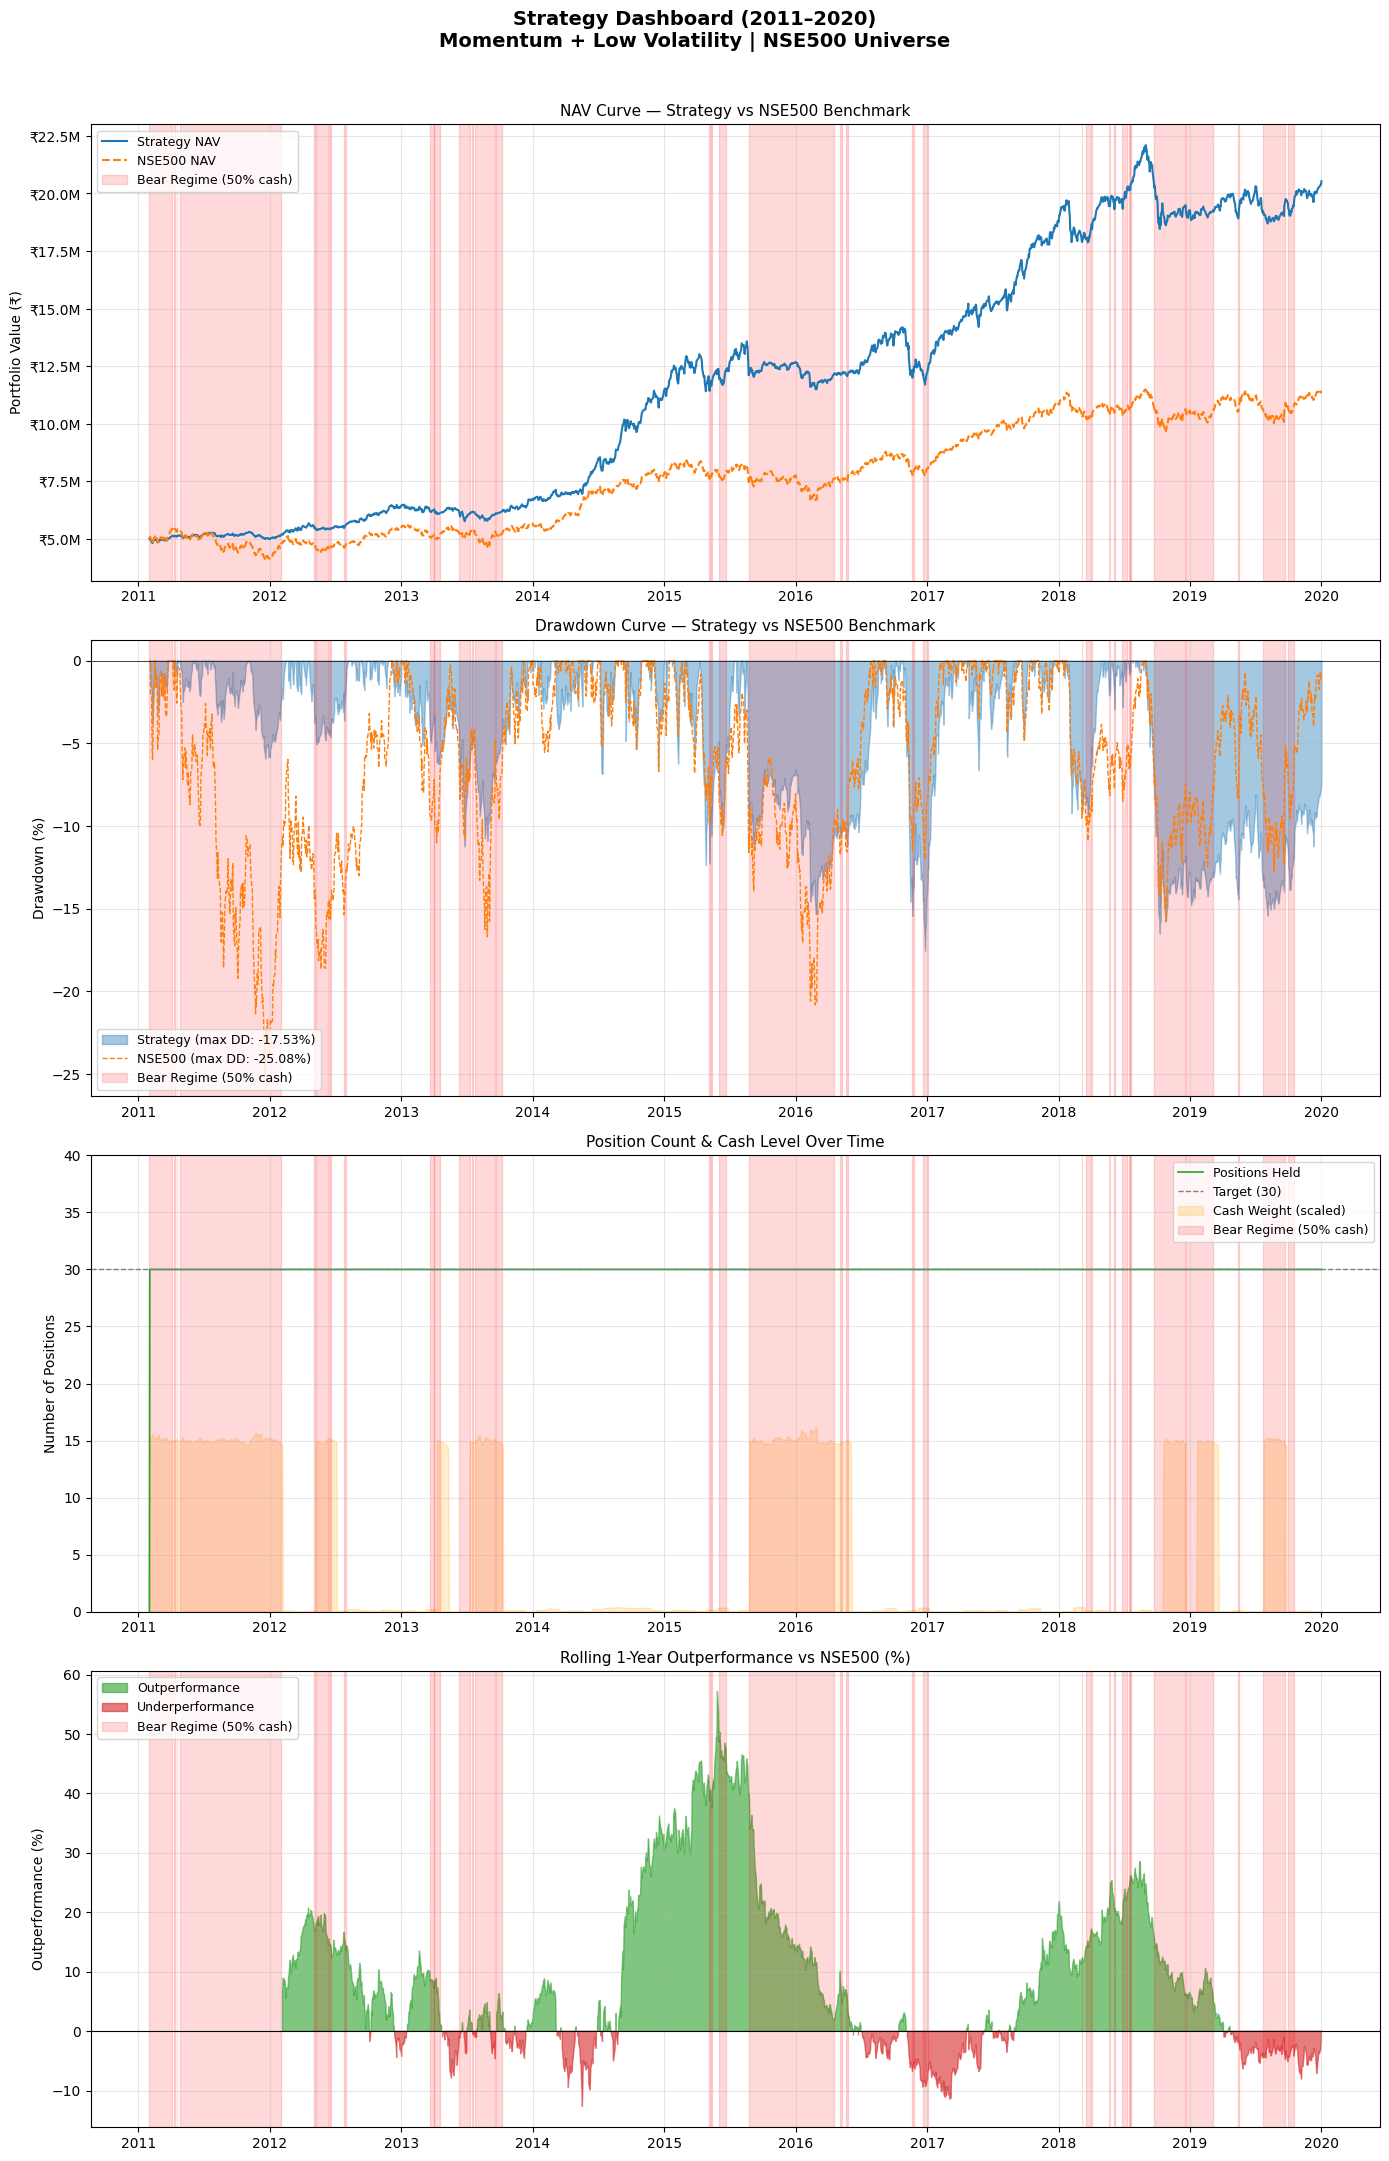

✓ Dashboard 1 saved: strategy_dashboard_2011_2020.png

REGIME BREAKDOWN STATISTICS
  Metric                                 Bull Regime    Bear Regime
  ---------------------------------------------------------------
  Trading Days                                  1464            743
  Ann. Return (Strategy)                      31.96%        -12.61%
  Ann. Return (Benchmark)                     23.65%        -15.45%
  Alpha vs Benchmark                           8.32%          2.84%
  Volatility (Strategy)                       13.27%         11.74%
  Daily Hit Rate vs BM                         52.9%          50.9%
  Up Capture                                   90.3%          46.6%
  Down Capture                                 74.1%          51.3%


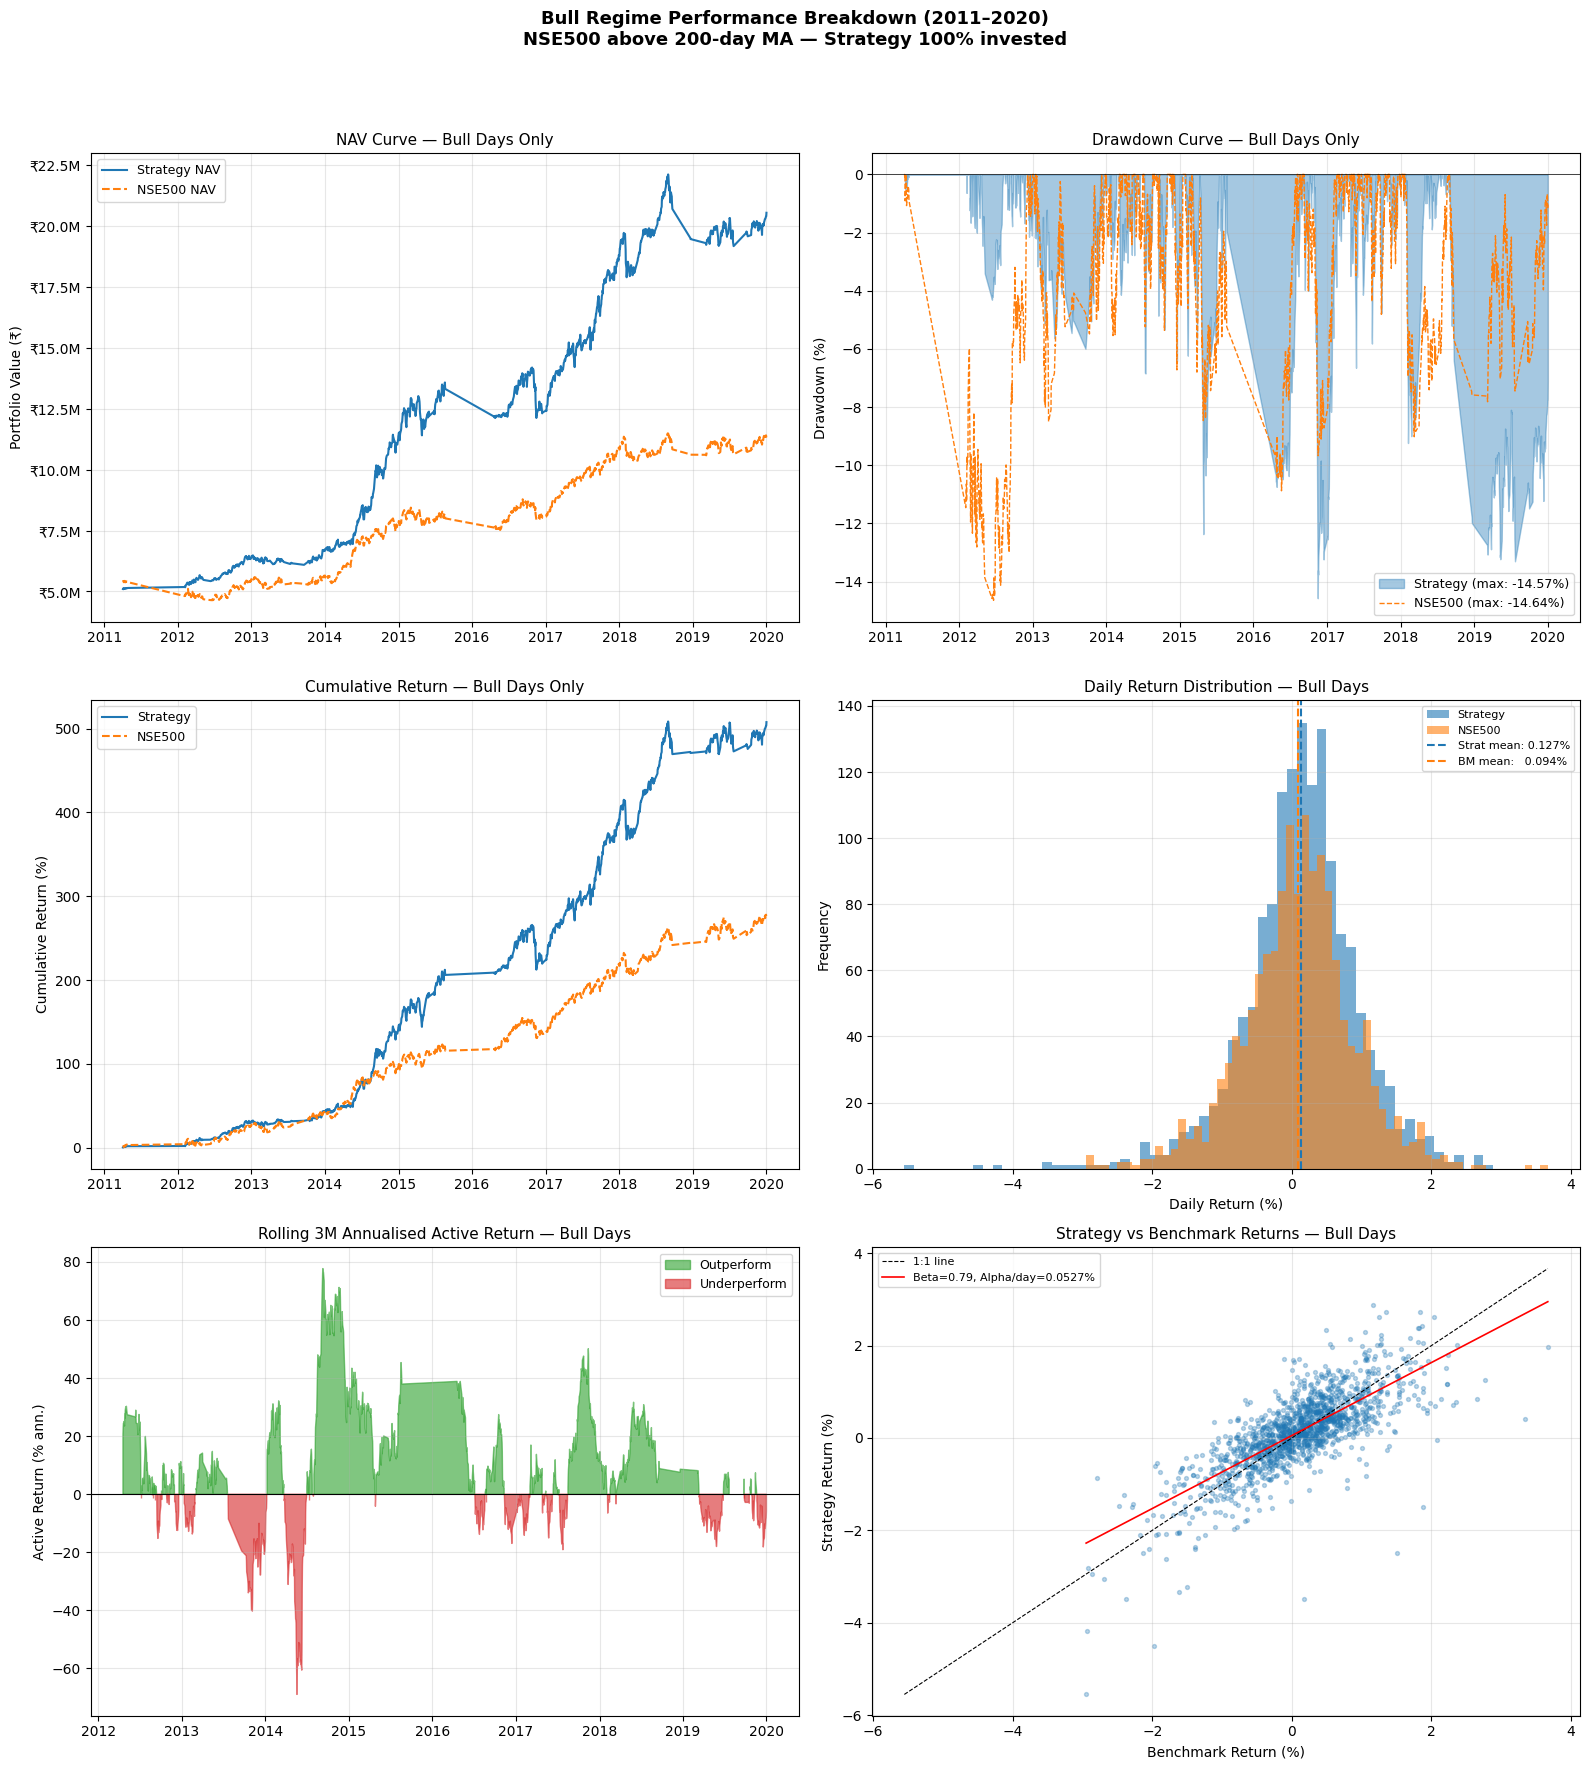

✓ Dashboard 2 saved: regime_bull_breakdown.png


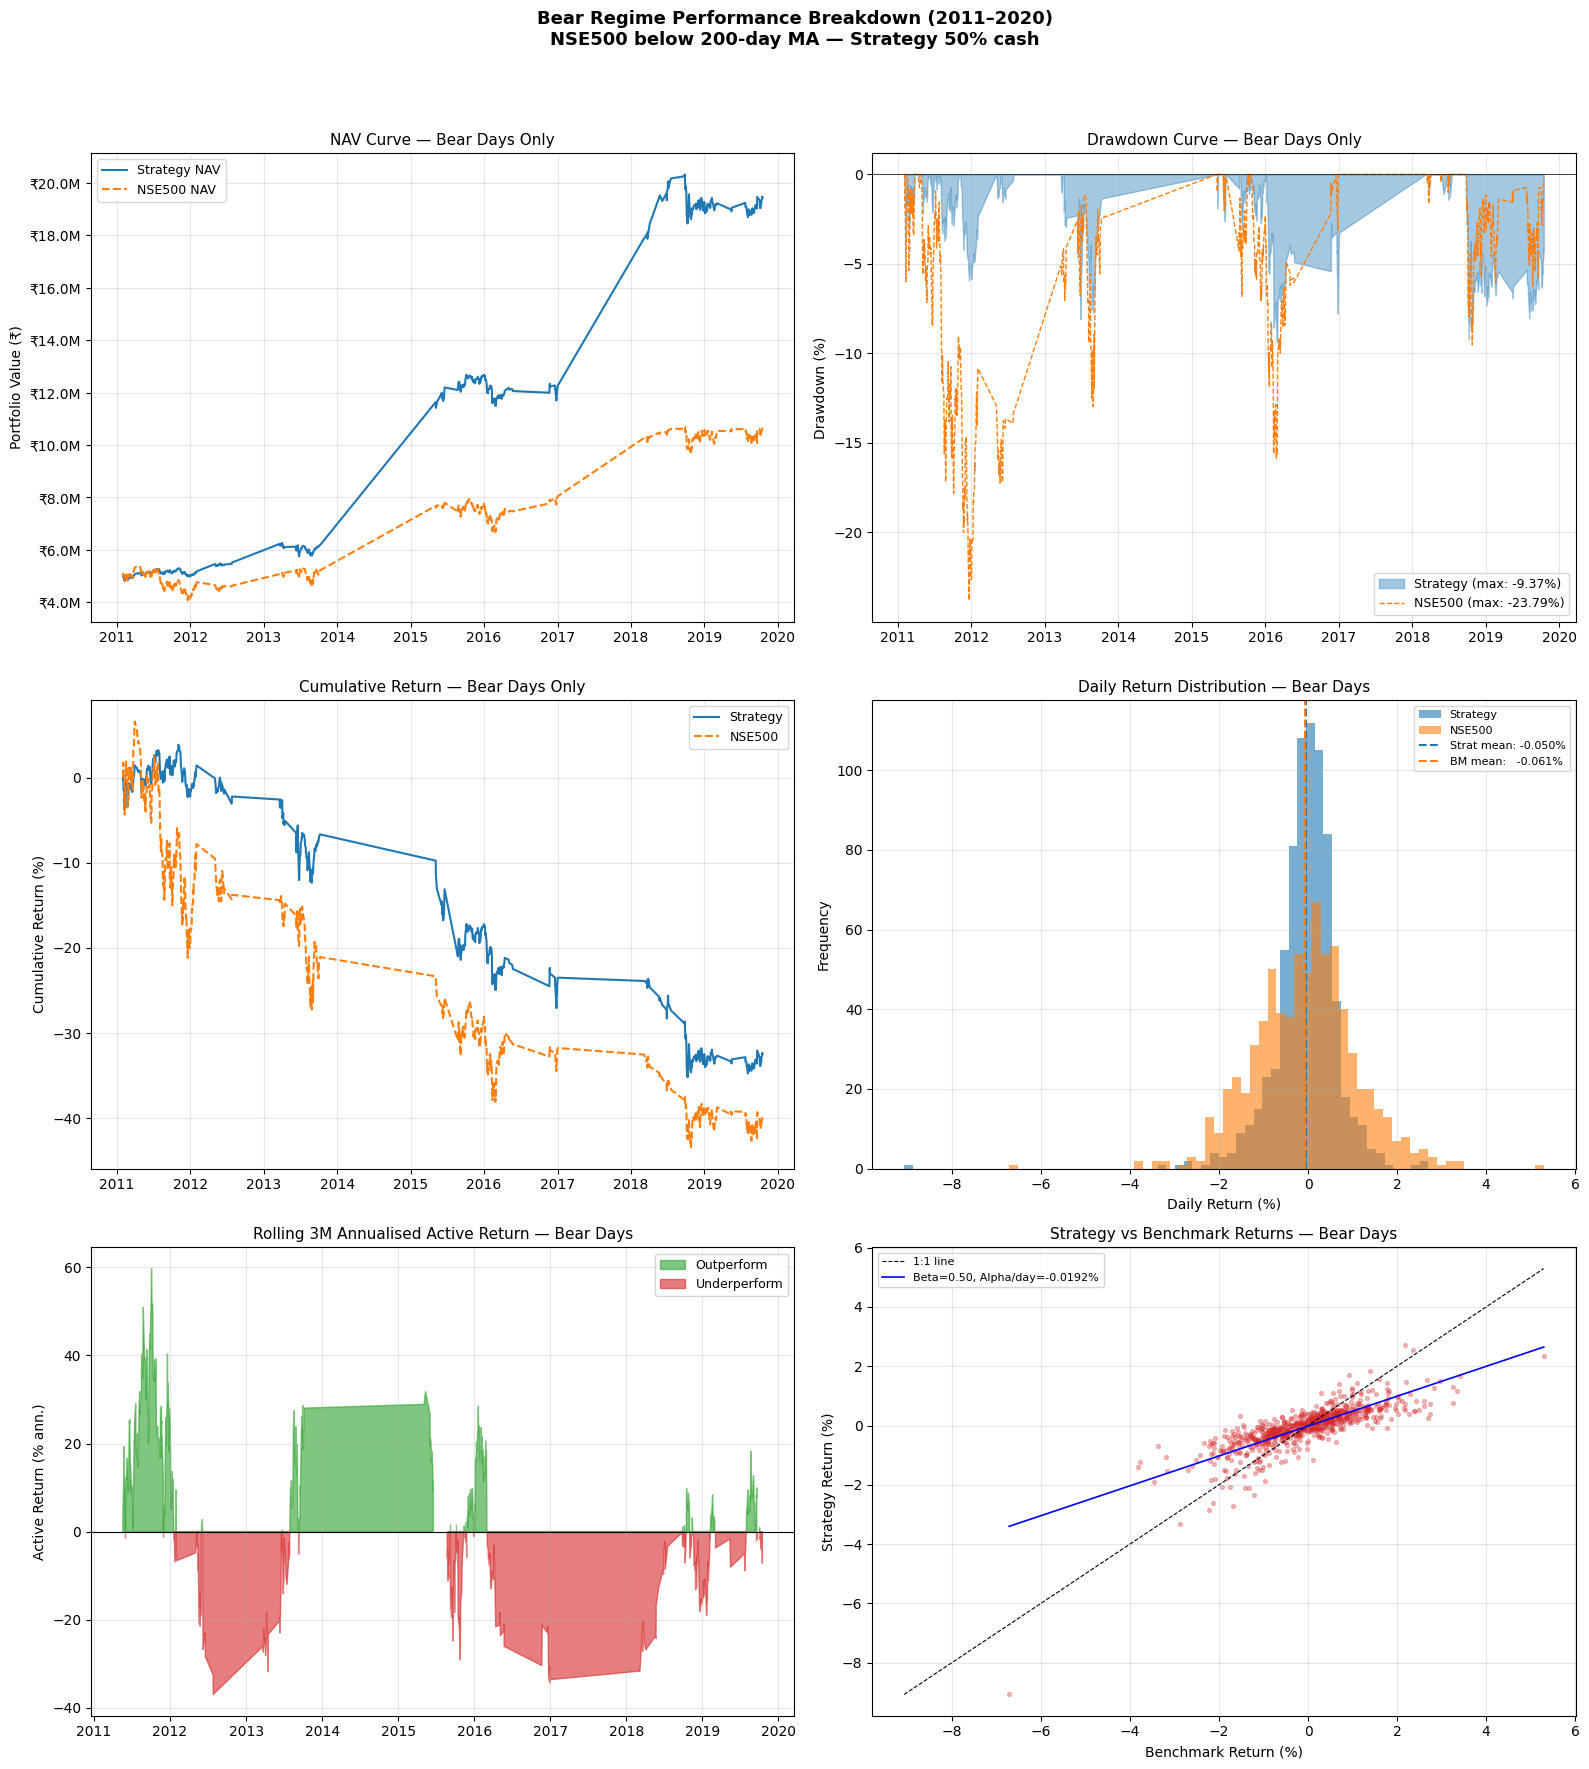

✓ Dashboard 3 saved: regime_bear_breakdown.png


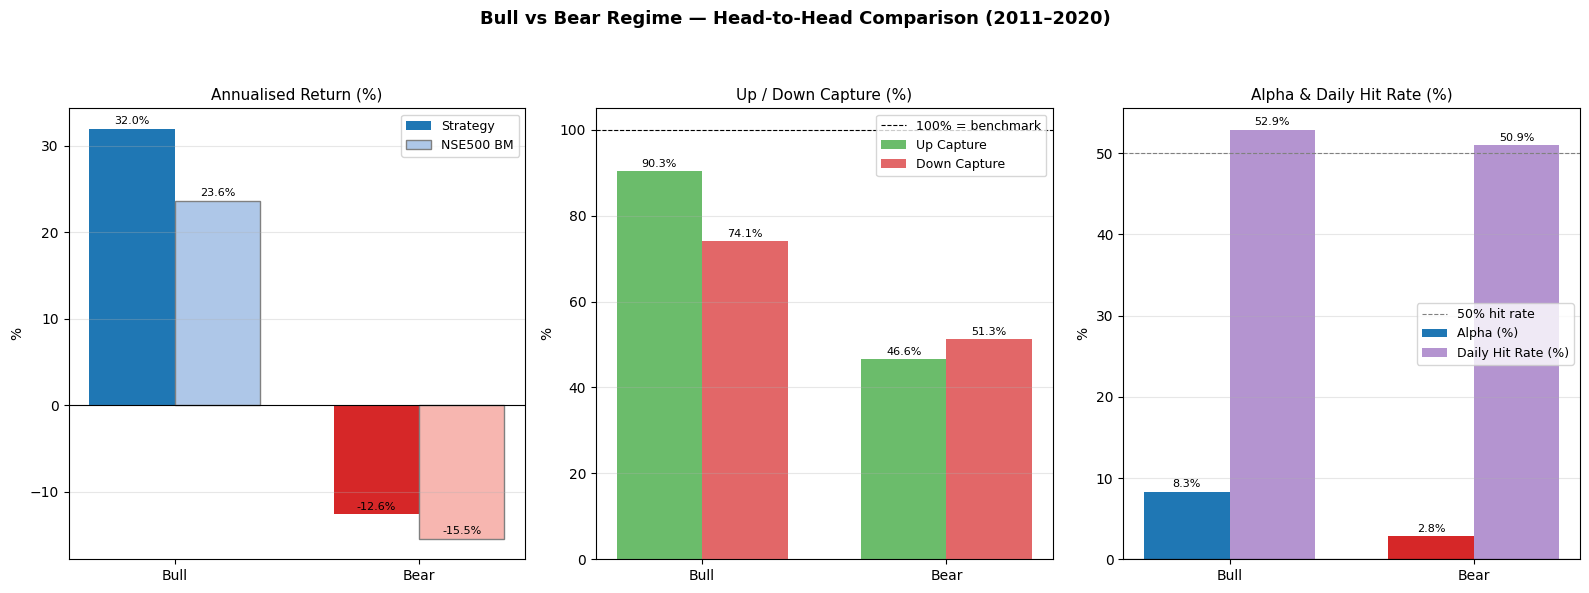

✓ Dashboard 4 saved: regime_comparison_bars.png

✓ All visualizations complete
  strategy_dashboard_2011_2020.png  — main dashboard (NAV + drawdown + positions + rolling outperf)
  regime_bull_breakdown.png         — bull: NAV, drawdown, cumret, distribution, active return, scatter
  regime_bear_breakdown.png         — bear: NAV, drawdown, cumret, distribution, active return, scatter
  regime_comparison_bars.png        — bull vs bear bars: return, capture, alpha, hit rate

ROLLING OUTPERFORMANCE SUMMARY (vs NSE500)
  Window        Avg Outperf   Worst Underperf   Best Outperf    Periods
  -----------------------------------------------------------------
  1Y                  8.83%           -12.67%         57.14%       1955
  3Y                  8.89%             1.04%         16.14%       1451
  5Y                  9.34%             5.08%         12.80%        947


In [25]:
# ============================================================================
# CELL 9: VISUALIZATIONS
# ============================================================================
print("\n" + "="*80)
print("CELL 9: VISUALIZATIONS")
print("="*80)

def shade_bear_periods(ax, results_df):
    label_added = False
    df = results_df.copy()
    in_bear    = False
    bear_start = None
    for _, row in df.iterrows():
        if row['bull_regime'] == 0 and not in_bear:
            bear_start = row['date']
            in_bear    = True
        elif row['bull_regime'] == 1 and in_bear:
            lbl = 'Bear Regime (50% cash)' if not label_added else '_nolegend_'
            ax.axvspan(bear_start, row['date'], alpha=0.15, color='red', label=lbl)
            label_added = True
            in_bear     = False
    if in_bear:
        lbl = 'Bear Regime (50% cash)' if not label_added else '_nolegend_'
        ax.axvspan(bear_start, df['date'].iloc[-1], alpha=0.15, color='red', label=lbl)


# ============================================================================
# DASHBOARD 1: MAIN 4-PANEL STRATEGY DASHBOARD
# ============================================================================
fig1, axes = plt.subplots(4, 1, figsize=(14, 22))
fig1.suptitle('Strategy Dashboard (2011–2020)\nMomentum + Low Volatility | NSE500 Universe',
              fontsize=14, fontweight='bold')

# Panel 1: NAV Curve
ax = axes[0]
ax.plot(perf_full['date'], perf_full['portfolio_value'],
        color='#1f77b4', linewidth=1.5, label='Strategy NAV')
ax.plot(perf_full['date'], perf_full['benchmark_value'],
        color='#ff7f0e', linewidth=1.5, linestyle='--', label='NSE500 NAV')
shade_bear_periods(ax, results_full)
ax.set_title('NAV Curve — Strategy vs NSE500 Benchmark', fontsize=11)
ax.set_ylabel('Portfolio Value (₹)')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'₹{x/1e6:.1f}M'))
ax.legend(loc='upper left', fontsize=9)
ax.grid(True, alpha=0.3)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.xaxis.set_major_locator(mdates.YearLocator())

# Panel 2: Drawdown Curve
ax = axes[1]
strat_max = perf_full['portfolio_value'].expanding().max()
strat_dd  = ((perf_full['portfolio_value'] - strat_max) / strat_max) * 100
bm_max    = perf_full['benchmark_value'].expanding().max()
bm_dd     = ((perf_full['benchmark_value'] - bm_max) / bm_max) * 100
ax.fill_between(perf_full['date'], strat_dd, 0,
                alpha=0.4, color='#1f77b4',
                label=f'Strategy (max DD: {strat_dd.min():.2f}%)')
ax.plot(perf_full['date'], bm_dd,
        color='#ff7f0e', linewidth=1.0, linestyle='--',
        label=f'NSE500 (max DD: {bm_dd.min():.2f}%)')
ax.axhline(0, color='black', linewidth=0.5)
shade_bear_periods(ax, results_full)
ax.set_title('Drawdown Curve — Strategy vs NSE500 Benchmark', fontsize=11)
ax.set_ylabel('Drawdown (%)')
ax.legend(loc='lower left', fontsize=9)
ax.grid(True, alpha=0.3)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.xaxis.set_major_locator(mdates.YearLocator())

# Panel 3: Position Count & Cash
ax = axes[2]
ax.plot(results_full['date'], results_full['positions'],
        color='#2ca02c', linewidth=1.2, label='Positions Held')
ax.axhline(y=TOP_N_STOCKS, color='gray', linestyle='--',
           linewidth=1.0, label=f'Target ({TOP_N_STOCKS})')
ax.fill_between(results_full['date'],
                results_full['cash'] / results_full['portfolio_value'] * MAX_POSITIONS,
                0, alpha=0.2, color='orange', label='Cash Weight (scaled)')
shade_bear_periods(ax, results_full)
ax.set_title('Position Count & Cash Level Over Time', fontsize=11)
ax.set_ylabel('Number of Positions')
ax.set_ylim(0, MAX_POSITIONS + 10)
ax.legend(loc='upper right', fontsize=9)
ax.grid(True, alpha=0.3)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.xaxis.set_major_locator(mdates.YearLocator())

# Panel 4: Rolling 1Y Outperformance
ax = axes[3]
s_r = (1 + perf_full['returns']).rolling(252).apply(
    lambda x: x.prod() ** (252/252) - 1, raw=True)
bm_r = (1 + perf_full['benchmark_returns']).rolling(252).apply(
    lambda x: x.prod() ** (252/252) - 1, raw=True)
rolling_1y = (s_r - bm_r) * 100
ax.fill_between(perf_full['date'], rolling_1y, 0,
                where=(rolling_1y >= 0), alpha=0.6, color='#2ca02c', label='Outperformance')
ax.fill_between(perf_full['date'], rolling_1y, 0,
                where=(rolling_1y < 0),  alpha=0.6, color='#d62728', label='Underperformance')
ax.axhline(y=0, color='black', linewidth=0.8)
shade_bear_periods(ax, results_full)
ax.set_title('Rolling 1-Year Outperformance vs NSE500 (%)', fontsize=11)
ax.set_ylabel('Outperformance (%)')
ax.legend(loc='upper left', fontsize=9)
ax.grid(True, alpha=0.3)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.xaxis.set_major_locator(mdates.YearLocator())

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.savefig('strategy_dashboard_2011_2020.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ Dashboard 1 saved: strategy_dashboard_2011_2020.png")


# ============================================================================
# SPLIT perf_full INTO BULL / BEAR SUBSETS
# ============================================================================
merged_regime = perf_full.merge(
    results_full[['date', 'bull_regime']], on='date', how='left'
)
bull_df = merged_regime[merged_regime['bull_regime'] == 1].copy().reset_index(drop=True)
bear_df = merged_regime[merged_regime['bull_regime'] == 0].copy().reset_index(drop=True)

# ── Per-regime stats ──────────────────────────────────────────────────────────
def regime_stats(df, label):
    if len(df) < 5:
        return {}
    s_ret = df['returns'].dropna()
    b_ret = df['benchmark_returns'].dropna()
    mr    = pd.DataFrame({'s': s_ret, 'b': b_ret}).dropna()
    up    = mr['b'] > 0
    dn    = mr['b'] < 0
    return {
        'label':         label,
        'days':          len(df),
        'ann_return':    s_ret.mean() * 252 * 100,
        'bm_ann_return': b_ret.mean() * 252 * 100,
        'alpha':         (s_ret.mean() - b_ret.mean()) * 252 * 100,
        'vol':           s_ret.std() * np.sqrt(252) * 100,
        'hit_rate':      (mr['s'] > mr['b']).mean() * 100,
        'up_capture':    (mr.loc[up,'s'].mean() / mr.loc[up,'b'].mean() * 100
                          if len(mr.loc[up]) > 0 and mr.loc[up,'b'].mean() != 0 else 0),
        'down_capture':  (mr.loc[dn,'s'].mean() / mr.loc[dn,'b'].mean() * 100
                          if len(mr.loc[dn]) > 0 and mr.loc[dn,'b'].mean() != 0 else 0),
    }

bull_stats = regime_stats(bull_df, 'Bull')
bear_stats = regime_stats(bear_df, 'Bear')

print("\nREGIME BREAKDOWN STATISTICS")
print("="*65)
print(f"  {'Metric':<35} {'Bull Regime':>14} {'Bear Regime':>14}")
print("  " + "-"*63)
for row in [
    ('Trading Days',             f"{bull_stats['days']}",               f"{bear_stats['days']}"),
    ('Ann. Return (Strategy)',   f"{bull_stats['ann_return']:.2f}%",    f"{bear_stats['ann_return']:.2f}%"),
    ('Ann. Return (Benchmark)',  f"{bull_stats['bm_ann_return']:.2f}%", f"{bear_stats['bm_ann_return']:.2f}%"),
    ('Alpha vs Benchmark',       f"{bull_stats['alpha']:.2f}%",         f"{bear_stats['alpha']:.2f}%"),
    ('Volatility (Strategy)',    f"{bull_stats['vol']:.2f}%",           f"{bear_stats['vol']:.2f}%"),
    ('Daily Hit Rate vs BM',    f"{bull_stats['hit_rate']:.1f}%",      f"{bear_stats['hit_rate']:.1f}%"),
    ('Up Capture',              f"{bull_stats['up_capture']:.1f}%",    f"{bear_stats['up_capture']:.1f}%"),
    ('Down Capture',            f"{bull_stats['down_capture']:.1f}%",  f"{bear_stats['down_capture']:.1f}%"),
]:
    print(f"  {row[0]:<35} {row[1]:>14} {row[2]:>14}")


# ============================================================================
# DASHBOARD 2: BULL REGIME — 6-PANEL (3 rows × 2 cols)
# ============================================================================
fig2, axes2 = plt.subplots(3, 2, figsize=(16, 18))
fig2.suptitle('Bull Regime Performance Breakdown (2011–2020)\n'
              'NSE500 above 200-day MA — Strategy 100% invested',
              fontsize=13, fontweight='bold')

# Row 1, Col 1: NAV Curve — bull days
ax = axes2[0, 0]
ax.plot(bull_df['date'], bull_df['portfolio_value'],
        color='#1f77b4', linewidth=1.5, label='Strategy NAV')
ax.plot(bull_df['date'], bull_df['benchmark_value'],
        color='#ff7f0e', linewidth=1.5, linestyle='--', label='NSE500 NAV')
ax.set_title('NAV Curve — Bull Days Only', fontsize=11)
ax.set_ylabel('Portfolio Value (₹)')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'₹{x/1e6:.1f}M'))
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.xaxis.set_major_locator(mdates.YearLocator())

# Row 1, Col 2: Drawdown Curve — bull days
ax = axes2[0, 1]
bull_s_max = bull_df['portfolio_value'].expanding().max()
bull_s_dd  = ((bull_df['portfolio_value'] - bull_s_max) / bull_s_max) * 100
bull_b_max = bull_df['benchmark_value'].expanding().max()
bull_b_dd  = ((bull_df['benchmark_value'] - bull_b_max) / bull_b_max) * 100
ax.fill_between(bull_df['date'], bull_s_dd, 0, alpha=0.4, color='#1f77b4',
                label=f'Strategy (max: {bull_s_dd.min():.2f}%)')
ax.plot(bull_df['date'], bull_b_dd, color='#ff7f0e', linewidth=1.0, linestyle='--',
        label=f'NSE500 (max: {bull_b_dd.min():.2f}%)')
ax.axhline(0, color='black', linewidth=0.5)
ax.set_title('Drawdown Curve — Bull Days Only', fontsize=11)
ax.set_ylabel('Drawdown (%)')
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.xaxis.set_major_locator(mdates.YearLocator())

# Row 2, Col 1: Cumulative return — bull days
ax = axes2[1, 0]
bull_s_cum = (1 + bull_df['returns'].fillna(0)).cumprod()
bull_b_cum = (1 + bull_df['benchmark_returns'].fillna(0)).cumprod()
ax.plot(bull_df['date'], (bull_s_cum - 1) * 100, color='#1f77b4', linewidth=1.5, label='Strategy')
ax.plot(bull_df['date'], (bull_b_cum - 1) * 100, color='#ff7f0e', linewidth=1.5,
        linestyle='--', label='NSE500')
ax.set_title('Cumulative Return — Bull Days Only', fontsize=11)
ax.set_ylabel('Cumulative Return (%)')
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.xaxis.set_major_locator(mdates.YearLocator())

# Row 2, Col 2: Daily return distribution — bull
ax = axes2[1, 1]
bull_mr = pd.DataFrame({'Strategy': bull_df['returns'].dropna() * 100,
                        'NSE500':   bull_df['benchmark_returns'].dropna() * 100})
ax.hist(bull_mr['Strategy'], bins=60, alpha=0.6, color='#1f77b4', label='Strategy')
ax.hist(bull_mr['NSE500'],   bins=60, alpha=0.6, color='#ff7f0e', label='NSE500')
ax.axvline(bull_mr['Strategy'].mean(), color='#1f77b4', linestyle='--', linewidth=1.5,
           label=f"Strat mean: {bull_mr['Strategy'].mean():.3f}%")
ax.axvline(bull_mr['NSE500'].mean(),   color='#ff7f0e', linestyle='--', linewidth=1.5,
           label=f"BM mean:   {bull_mr['NSE500'].mean():.3f}%")
ax.set_title('Daily Return Distribution — Bull Days', fontsize=11)
ax.set_xlabel('Daily Return (%)')
ax.set_ylabel('Frequency')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

# Row 3, Col 1: Rolling 3M active return — bull
ax = axes2[2, 0]
bull_active     = bull_df['returns'].fillna(0) - bull_df['benchmark_returns'].fillna(0)
rolling_3m_bull = bull_active.rolling(63).mean() * 252 * 100
ax.fill_between(bull_df['date'], rolling_3m_bull, 0,
                where=(rolling_3m_bull >= 0), alpha=0.6, color='#2ca02c', label='Outperform')
ax.fill_between(bull_df['date'], rolling_3m_bull, 0,
                where=(rolling_3m_bull < 0),  alpha=0.6, color='#d62728', label='Underperform')
ax.axhline(0, color='black', linewidth=0.8)
ax.set_title('Rolling 3M Annualised Active Return — Bull Days', fontsize=11)
ax.set_ylabel('Active Return (% ann.)')
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.xaxis.set_major_locator(mdates.YearLocator())

# Row 3, Col 2: Scatter — bull
ax = axes2[2, 1]
common_bull = pd.DataFrame({
    'bm': bull_df['benchmark_returns'].dropna() * 100,
    'st': bull_df['returns'].dropna() * 100
}).dropna()
ax.scatter(common_bull['bm'], common_bull['st'], alpha=0.3, s=8, color='#1f77b4')
lims = [min(common_bull['bm'].min(), common_bull['st'].min()),
        max(common_bull['bm'].max(), common_bull['st'].max())]
ax.plot(lims, lims, 'k--', linewidth=0.8, label='1:1 line')
m, b = np.polyfit(common_bull['bm'], common_bull['st'], 1)
xfit = np.linspace(common_bull['bm'].min(), common_bull['bm'].max(), 100)
ax.plot(xfit, m * xfit + b, color='red', linewidth=1.2,
        label=f'Beta={m:.2f}, Alpha/day={b:.4f}%')
ax.set_title('Strategy vs Benchmark Returns — Bull Days', fontsize=11)
ax.set_xlabel('Benchmark Return (%)')
ax.set_ylabel('Strategy Return (%)')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig('regime_bull_breakdown.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ Dashboard 2 saved: regime_bull_breakdown.png")


# ============================================================================
# DASHBOARD 3: BEAR REGIME 
# ============================================================================
fig3, axes3 = plt.subplots(3, 2, figsize=(16, 18))
fig3.suptitle('Bear Regime Performance Breakdown (2011–2020)\n'
              'NSE500 below 200-day MA — Strategy 50% cash',
              fontsize=13, fontweight='bold')

# Row 1, Col 1: NAV Curve — bear days
ax = axes3[0, 0]
ax.plot(bear_df['date'], bear_df['portfolio_value'],
        color='#1f77b4', linewidth=1.5, label='Strategy NAV')
ax.plot(bear_df['date'], bear_df['benchmark_value'],
        color='#ff7f0e', linewidth=1.5, linestyle='--', label='NSE500 NAV')
ax.set_title('NAV Curve — Bear Days Only', fontsize=11)
ax.set_ylabel('Portfolio Value (₹)')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'₹{x/1e6:.1f}M'))
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.xaxis.set_major_locator(mdates.YearLocator())

# Row 1, Col 2: Drawdown Curve — bear days
ax = axes3[0, 1]
bear_s_max = bear_df['portfolio_value'].expanding().max()
bear_s_dd  = ((bear_df['portfolio_value'] - bear_s_max) / bear_s_max) * 100
bear_b_max = bear_df['benchmark_value'].expanding().max()
bear_b_dd  = ((bear_df['benchmark_value'] - bear_b_max) / bear_b_max) * 100
ax.fill_between(bear_df['date'], bear_s_dd, 0, alpha=0.4, color='#1f77b4',
                label=f'Strategy (max: {bear_s_dd.min():.2f}%)')
ax.plot(bear_df['date'], bear_b_dd, color='#ff7f0e', linewidth=1.0, linestyle='--',
        label=f'NSE500 (max: {bear_b_dd.min():.2f}%)')
ax.axhline(0, color='black', linewidth=0.5)
ax.set_title('Drawdown Curve — Bear Days Only', fontsize=11)
ax.set_ylabel('Drawdown (%)')
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.xaxis.set_major_locator(mdates.YearLocator())

# Row 2, Col 1: Cumulative return — bear days
ax = axes3[1, 0]
bear_s_cum = (1 + bear_df['returns'].fillna(0)).cumprod()
bear_b_cum = (1 + bear_df['benchmark_returns'].fillna(0)).cumprod()
ax.plot(bear_df['date'], (bear_s_cum - 1) * 100, color='#1f77b4', linewidth=1.5, label='Strategy')
ax.plot(bear_df['date'], (bear_b_cum - 1) * 100, color='#ff7f0e', linewidth=1.5,
        linestyle='--', label='NSE500')
ax.set_title('Cumulative Return — Bear Days Only', fontsize=11)
ax.set_ylabel('Cumulative Return (%)')
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.xaxis.set_major_locator(mdates.YearLocator())

# Row 2, Col 2: Daily return distribution — bear
ax = axes3[1, 1]
bear_mr = pd.DataFrame({'Strategy': bear_df['returns'].dropna() * 100,
                        'NSE500':   bear_df['benchmark_returns'].dropna() * 100})
ax.hist(bear_mr['Strategy'], bins=60, alpha=0.6, color='#1f77b4', label='Strategy')
ax.hist(bear_mr['NSE500'],   bins=60, alpha=0.6, color='#ff7f0e', label='NSE500')
ax.axvline(bear_mr['Strategy'].mean(), color='#1f77b4', linestyle='--', linewidth=1.5,
           label=f"Strat mean: {bear_mr['Strategy'].mean():.3f}%")
ax.axvline(bear_mr['NSE500'].mean(),   color='#ff7f0e', linestyle='--', linewidth=1.5,
           label=f"BM mean:   {bear_mr['NSE500'].mean():.3f}%")
ax.set_title('Daily Return Distribution — Bear Days', fontsize=11)
ax.set_xlabel('Daily Return (%)')
ax.set_ylabel('Frequency')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

# Row 3, Col 1: Rolling 3M active return — bear
ax = axes3[2, 0]
bear_active     = bear_df['returns'].fillna(0) - bear_df['benchmark_returns'].fillna(0)
rolling_3m_bear = bear_active.rolling(63).mean() * 252 * 100
ax.fill_between(bear_df['date'], rolling_3m_bear, 0,
                where=(rolling_3m_bear >= 0), alpha=0.6, color='#2ca02c', label='Outperform')
ax.fill_between(bear_df['date'], rolling_3m_bear, 0,
                where=(rolling_3m_bear < 0),  alpha=0.6, color='#d62728', label='Underperform')
ax.axhline(0, color='black', linewidth=0.8)
ax.set_title('Rolling 3M Annualised Active Return — Bear Days', fontsize=11)
ax.set_ylabel('Active Return (% ann.)')
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.xaxis.set_major_locator(mdates.YearLocator())

# Row 3, Col 2: Scatter — bear
ax = axes3[2, 1]
common_bear = pd.DataFrame({
    'bm': bear_df['benchmark_returns'].dropna() * 100,
    'st': bear_df['returns'].dropna() * 100
}).dropna()
ax.scatter(common_bear['bm'], common_bear['st'], alpha=0.3, s=8, color='#d62728')
lims2 = [min(common_bear['bm'].min(), common_bear['st'].min()),
         max(common_bear['bm'].max(), common_bear['st'].max())]
ax.plot(lims2, lims2, 'k--', linewidth=0.8, label='1:1 line')
m2, b2 = np.polyfit(common_bear['bm'], common_bear['st'], 1)
xfit2  = np.linspace(common_bear['bm'].min(), common_bear['bm'].max(), 100)
ax.plot(xfit2, m2 * xfit2 + b2, color='blue', linewidth=1.2,
        label=f'Beta={m2:.2f}, Alpha/day={b2:.4f}%')
ax.set_title('Strategy vs Benchmark Returns — Bear Days', fontsize=11)
ax.set_xlabel('Benchmark Return (%)')
ax.set_ylabel('Strategy Return (%)')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig('regime_bear_breakdown.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ Dashboard 3 saved: regime_bear_breakdown.png")


# ============================================================================
# DASHBOARD 4: BULL vs BEAR SIDE-BY-SIDE BAR COMPARISON
# ============================================================================
fig4, axes4 = plt.subplots(1, 3, figsize=(16, 6))
fig4.suptitle('Bull vs Bear Regime — Head-to-Head Comparison (2011–2020)',
              fontsize=13, fontweight='bold')

regimes  = ['Bull', 'Bear']
x        = np.arange(2)
w        = 0.35

# Bar 1: Annualised return
ax = axes4[0]
strat_rets = [bull_stats['ann_return'],    bear_stats['ann_return']]
bm_rets    = [bull_stats['bm_ann_return'], bear_stats['bm_ann_return']]
ax.bar(x - w/2, strat_rets, w, label='Strategy',  color=['#1f77b4','#d62728'])
ax.bar(x + w/2, bm_rets,    w, label='NSE500 BM', color=['#aec7e8','#f7b6b0'], edgecolor='gray')
ax.axhline(0, color='black', linewidth=0.8)
ax.set_title('Annualised Return (%)', fontsize=11)
ax.set_ylabel('%')
ax.set_xticks(x)
ax.set_xticklabels(regimes)
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3, axis='y')
for i, (sv, bv) in enumerate(zip(strat_rets, bm_rets)):
    ax.text(i - w/2, sv + 0.3, f'{sv:.1f}%', ha='center', va='bottom', fontsize=8)
    ax.text(i + w/2, bv + 0.3, f'{bv:.1f}%', ha='center', va='bottom', fontsize=8)

# Bar 2: Up/Down capture
ax = axes4[1]
up_caps = [bull_stats['up_capture'],   bear_stats['up_capture']]
dn_caps = [bull_stats['down_capture'], bear_stats['down_capture']]
ax.bar(x - w/2, up_caps, w, label='Up Capture',   color='#2ca02c', alpha=0.7)
ax.bar(x + w/2, dn_caps, w, label='Down Capture', color='#d62728', alpha=0.7)
ax.axhline(100, color='black', linestyle='--', linewidth=0.8, label='100% = benchmark')
ax.set_title('Up / Down Capture (%)', fontsize=11)
ax.set_ylabel('%')
ax.set_xticks(x)
ax.set_xticklabels(regimes)
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3, axis='y')
for i, (u, d) in enumerate(zip(up_caps, dn_caps)):
    ax.text(i - w/2, u + 0.5, f'{u:.1f}%', ha='center', va='bottom', fontsize=8)
    ax.text(i + w/2, d + 0.5, f'{d:.1f}%', ha='center', va='bottom', fontsize=8)

# Bar 3: Alpha and Hit Rate
ax = axes4[2]
alphas   = [bull_stats['alpha'],    bear_stats['alpha']]
hitrates = [bull_stats['hit_rate'], bear_stats['hit_rate']]
ax.bar(x - w/2, alphas,   w, label='Alpha (%)',          color=['#1f77b4','#d62728'])
ax.bar(x + w/2, hitrates, w, label='Daily Hit Rate (%)', color='#9467bd', alpha=0.7)
ax.axhline(0,  color='black', linewidth=0.8)
ax.axhline(50, color='gray',  linewidth=0.8, linestyle='--', label='50% hit rate')
ax.set_title('Alpha & Daily Hit Rate (%)', fontsize=11)
ax.set_ylabel('%')
ax.set_xticks(x)
ax.set_xticklabels(regimes)
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3, axis='y')
for i, (a, h) in enumerate(zip(alphas, hitrates)):
    ax.text(i - w/2, a + 0.3, f'{a:.1f}%', ha='center', va='bottom', fontsize=8)
    ax.text(i + w/2, h + 0.3, f'{h:.1f}%', ha='center', va='bottom', fontsize=8)

plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.savefig('regime_comparison_bars.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ Dashboard 4 saved: regime_comparison_bars.png")

print("\n✓ All visualizations complete")
print("  strategy_dashboard_2011_2020.png  — main dashboard (NAV + drawdown + positions + rolling outperf)")
print("  regime_bull_breakdown.png         — bull: NAV, drawdown, cumret, distribution, active return, scatter")
print("  regime_bear_breakdown.png         — bear: NAV, drawdown, cumret, distribution, active return, scatter")
print("  regime_comparison_bars.png        — bull vs bear bars: return, capture, alpha, hit rate")

# ── Rolling Outperformance Summary ───────────────────────────────────────────
print("\n" + "="*70)
print("ROLLING OUTPERFORMANCE SUMMARY (vs NSE500)")
print("="*70)
print(f"  {'Window':<10} {'Avg Outperf':>14} {'Worst Underperf':>17} "
      f"{'Best Outperf':>14} {'Periods':>10}")
print("  " + "-"*65)
for period, m in rolling_metrics.items():
    print(f"  {period:<10} "
          f"{m['Average Outperformance']:>14} "
          f"{m['Worst Underperformance']:>17} "
          f"{m['Best Outperformance']:>14} "
          f"{str(m['Periods Analyzed']):>10}")


ROLLING OUTPERFORMANCE CHARTS — 1Y, 3Y, 5Y


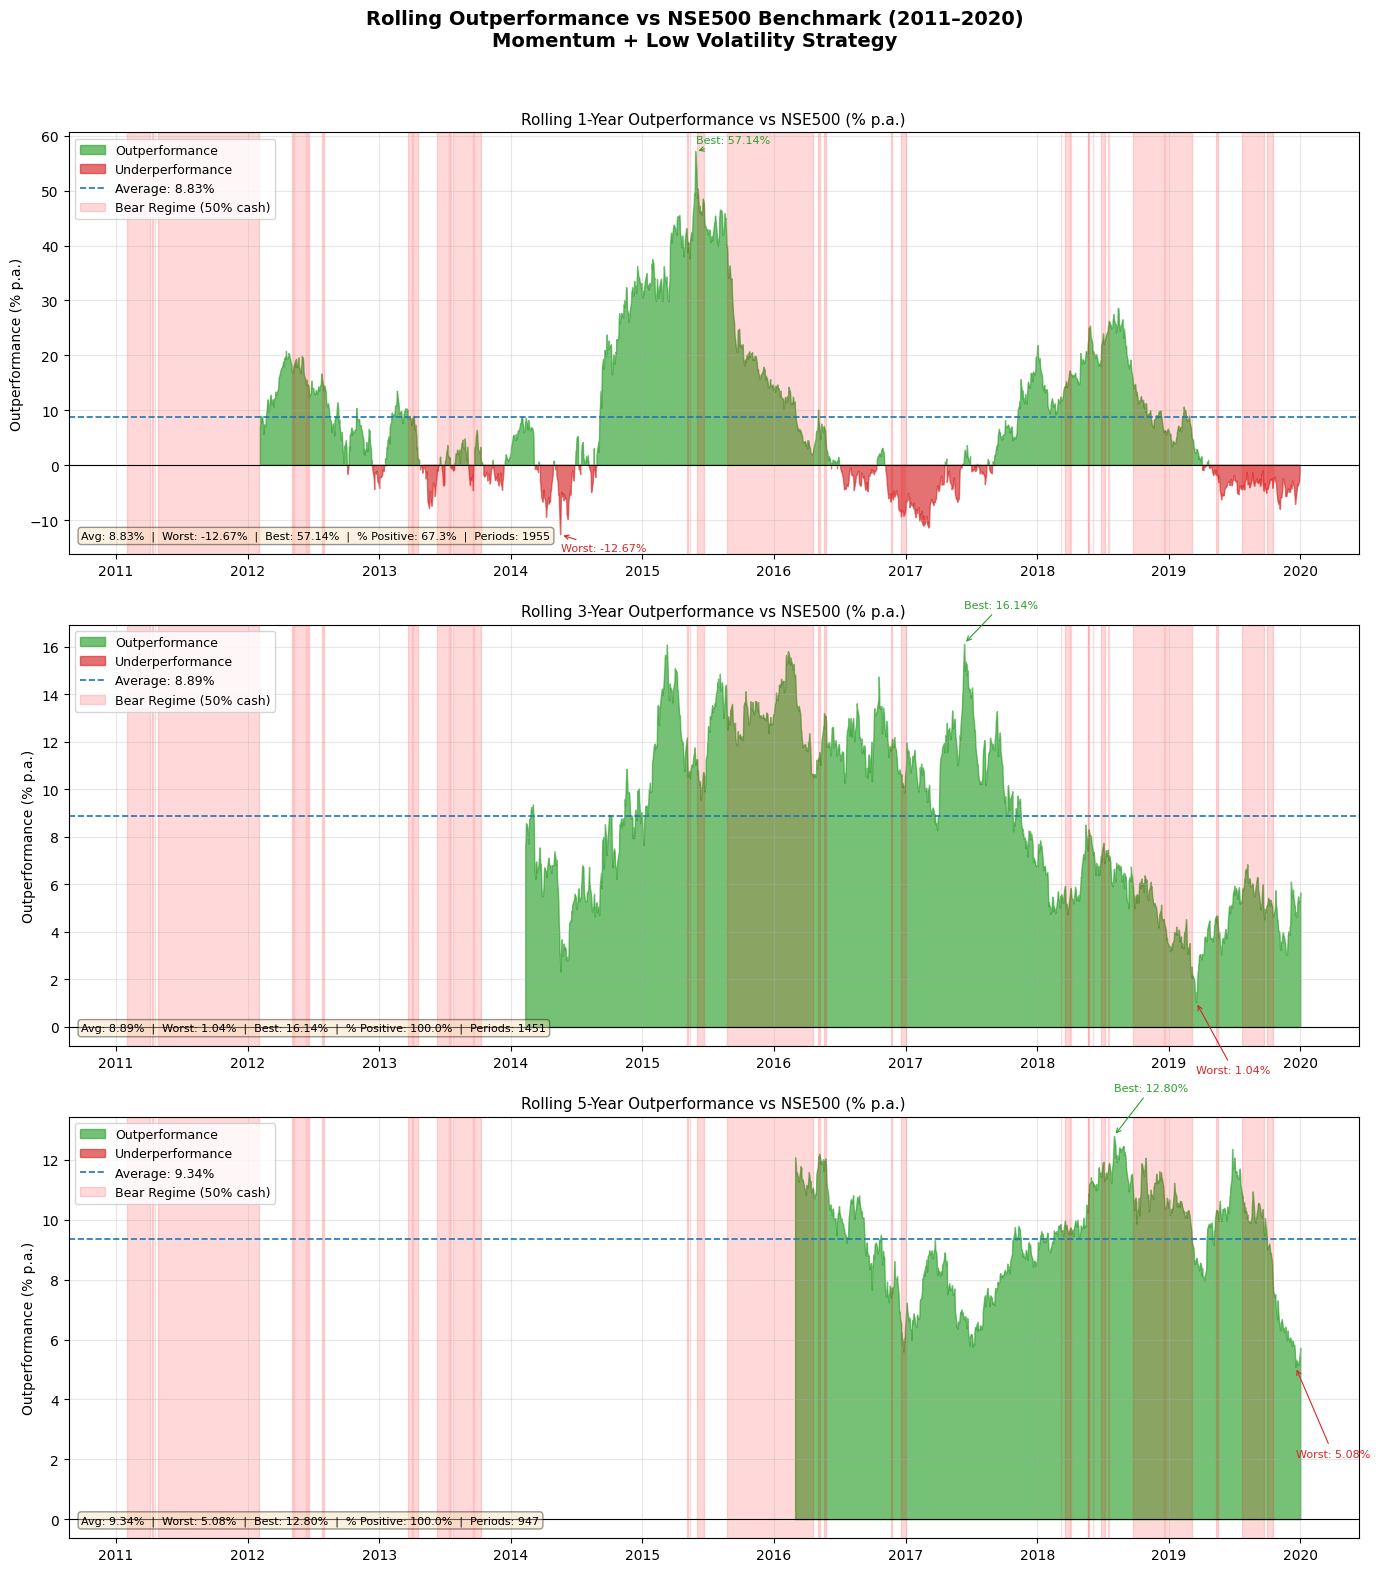

✓ Saved: rolling_outperformance_1Y_3Y_5Y.png

ROLLING OUTPERFORMANCE SUMMARY
  Window        Avg      Worst       Best    % +ve    Periods
  ----------------------------------------------------------
  1-YearY     8.83%    -12.67%     57.14%    67.3%       1955
  3-YearY     8.89%      1.04%     16.14%   100.0%       1451
  5-YearY     9.34%      5.08%     12.80%   100.0%        947


In [30]:
# ============================================================================
# CELL: ROLLING OUTPERFORMANCE CHARTS (1Y, 3Y, 5Y)
# ============================================================================
print("\n" + "="*80)
print("ROLLING OUTPERFORMANCE CHARTS — 1Y, 3Y, 5Y")
print("="*80)

fig, axes = plt.subplots(3, 1, figsize=(14, 16))
fig.suptitle('Rolling Outperformance vs NSE500 Benchmark (2011–2020)\n'
             'Momentum + Low Volatility Strategy',
             fontsize=14, fontweight='bold')

windows = [
    (252,  '1',  '1-Year'),
    (756,  '3',  '3-Year'),
    (1260, '5',  '5-Year'),
]

for ax, (window, yr, label) in zip(axes, windows):

    s_r = (1 + perf_full['returns']).rolling(window).apply(
        lambda x: x.prod() ** (252 / window) - 1, raw=True
    )
    bm_r = (1 + perf_full['benchmark_returns']).rolling(window).apply(
        lambda x: x.prod() ** (252 / window) - 1, raw=True
    )
    outperf = (s_r - bm_r) * 100

    # Fill above/below zero
    ax.fill_between(perf_full['date'], outperf, 0,
                    where=(outperf >= 0),
                    alpha=0.65, color='#2ca02c', label='Outperformance')
    ax.fill_between(perf_full['date'], outperf, 0,
                    where=(outperf < 0),
                    alpha=0.65, color='#d62728', label='Underperformance')

    # Zero line
    ax.axhline(0, color='black', linewidth=0.8)

    # Average outperformance line
    avg = outperf.mean()
    ax.axhline(avg, color='#1f77b4', linewidth=1.2, linestyle='--',
               label=f'Average: {avg:.2f}%')

    # Worst and best annotations
    worst = outperf.min()
    best  = outperf.max()
    worst_date = perf_full['date'][outperf.idxmin()] if outperf.notna().any() else None
    best_date  = perf_full['date'][outperf.idxmax()] if outperf.notna().any() else None

    if worst_date is not None:
        ax.annotate(f'Worst: {worst:.2f}%',
                    xy=(worst_date, worst),
                    xytext=(worst_date, worst - 3),
                    fontsize=8, color='#d62728',
                    arrowprops=dict(arrowstyle='->', color='#d62728', lw=0.8))

    if best_date is not None:
        ax.annotate(f'Best: {best:.2f}%',
                    xy=(best_date, best),
                    xytext=(best_date, best + 1.5),
                    fontsize=8, color='#2ca02c',
                    arrowprops=dict(arrowstyle='->', color='#2ca02c', lw=0.8))

    # Bear period shading
    shade_bear_periods(ax, results_full)

    # Stats box
    periods_analyzed = outperf.notna().sum()
    pct_positive     = (outperf > 0).sum() / periods_analyzed * 100 if periods_analyzed > 0 else 0
    stats_text = (f'Avg: {avg:.2f}%  |  '
                  f'Worst: {worst:.2f}%  |  '
                  f'Best: {best:.2f}%  |  '
                  f'% Positive: {pct_positive:.1f}%  |  '
                  f'Periods: {periods_analyzed}')
    ax.text(0.01, 0.03, stats_text,
            transform=ax.transAxes, fontsize=8,
            verticalalignment='bottom',
            bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.4))

    ax.set_title(f'Rolling {label} Outperformance vs NSE500 (% p.a.)', fontsize=11)
    ax.set_ylabel('Outperformance (% p.a.)')
    ax.legend(loc='upper left', fontsize=9)
    ax.grid(True, alpha=0.3)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    ax.xaxis.set_major_locator(mdates.YearLocator())

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig('rolling_outperformance_1Y_3Y_5Y.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ Saved: rolling_outperformance_1Y_3Y_5Y.png")

# ── Summary table ─────────────────────────────────────────────────────────────
print("\n" + "="*70)
print("ROLLING OUTPERFORMANCE SUMMARY")
print("="*70)
print(f"  {'Window':<8} {'Avg':>8} {'Worst':>10} {'Best':>10} "
      f"{'% +ve':>8} {'Periods':>10}")
print("  " + "-"*58)

for window, yr, label in windows:
    s_r  = (1 + perf_full['returns']).rolling(window).apply(
        lambda x: x.prod() ** (252/window) - 1, raw=True)
    bm_r = (1 + perf_full['benchmark_returns']).rolling(window).apply(
        lambda x: x.prod() ** (252/window) - 1, raw=True)
    out  = (s_r - bm_r) * 100
    n    = out.notna().sum()
    pct  = (out > 0).sum() / n * 100 if n > 0 else 0
    print(f"  {label+'Y':<8} {out.mean():>7.2f}% {out.min():>9.2f}% "
          f"{out.max():>9.2f}% {pct:>7.1f}% {n:>10}")